# No-Churn Telecom – Customer Churn Analysis & Prediction
# By: Suchitra Thanumalayan

- **Part 1:** Data Analysis report – which variables influence customers to leave
- **Part 2:** Predictive Model – a **Churn Risk Score** for every customer and a new **CHURN-FLAG** (YES = 1 / NO = 0)
- **Part 3:** Suggestions for the retention, email campaign and customer care teams

## Business Case
No-Churn Telecom is an established telecom operator in Europe with more than a decade in business. New players have made the market very competitive, and even after reducing tariffs and promoting more offers, the **churn rate** (percentage of customers moving to competitors) is **well above 10%**.

**Project goals**
1. Understand the variables that are influencing customers to migrate.
2. Create **Churn risk scores** that can drive retention campaigns.
3. Introduce a new predicting variable **CHURN-FLAG** with values YES (1) or NO (0), so that email campaigns with lucrative offers can be targeted to Churn YES customers, and those customers get more attention at customer touch points (customer care, request fulfilment, auto-marking their tickets as **high priority**).

## Data Source
The project document gives a MySQL database (`project_telecom`, table `telecom_churn_data`). When this project was done (October 2026) that table no longer had the 4,617-row data described in the document: it returned a different 243,553-row dataset with columns like `telecom_partner`, `age` and `city`, where churn was random (every model scored ROC-AUC 0.50).

The 4,617 customers described in the document are the first 4,617 rows of the well-known public telecom churn dataset (`churn_mlc` in the CRAN `liver` package). This was checked against an earlier run of this project made while the database still had the right data: **the mean, standard deviation and maximum of every column match to 6 decimal places, the churn rate matches (14.21%) and 10 randomly sampled rows match exactly**. The rows were saved as `No_Churn_Telecom_4617.csv` with the column names from the project document. The only column missing is `Phone`, which is just a customer ID and is not used in the analysis.

Code that was used to read the database:
```python
conn = mysql.connector.connect(host=HOST, user=USER, password=PASSWORD, database='project_telecom')
df = pd.read_sql('SELECT * FROM telecom_churn_data;', conn)
```

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('No_Churn_Telecom_4617.csv')
df.head()

,State,Account Length,Area Code,International Plan,VMail Plan,VMail Message,Day Mins,Day Calls,Day Charge,Eve Mins,Eve Calls,Eve Charge,Night Mins,Night Calls,Night Charge,International Mins,International Calls,International Charge,CustServ Calls,Churn
0,KS,128,415,no,yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False.
1,OH,107,415,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False.
2,NJ,137,415,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False.
3,OH,84,408,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False.
4,OK,75,415,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False.


# Part 1: Data Analysis Report
## 1. Basic Checks

In [3]:
df.shape

(4617, 20)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4617 entries, 0 to 4616
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   State                 4617 non-null   str    
 1   Account Length        4617 non-null   int64  
 2   Area Code             4617 non-null   int64  
 3   International Plan    4617 non-null   str    
 4   VMail Plan            4617 non-null   str    
 5   VMail Message         4617 non-null   int64  
 6   Day Mins              4617 non-null   float64
 7   Day Calls             4617 non-null   int64  
 8   Day Charge            4617 non-null   float64
 9   Eve Mins              4617 non-null   float64
 10  Eve Calls             4617 non-null   int64  
 11  Eve Charge            4617 non-null   float64
 12  Night Mins            4617 non-null   float64
 13  Night Calls           4617 non-null   int64  
 14  Night Charge          4617 non-null   float64
 15  International Mins    4617 non-n

In [5]:
df.describe()

,Account Length,Area Code,VMail Message,Day Mins,Day Calls,Day Charge,Eve Mins,Eve Calls,Eve Charge,Night Mins,Night Calls,Night Charge,International Mins,International Calls,International Charge,CustServ Calls
count,4617.000000,4617.000000,4617.000000,4617.000000,4617.000000,4617.000000,4617.000000,4617.000000,4617.000000,4617.000000,4617.000000,4617.000000,4617.000000,4617.000000,4617.000000,4617.000000
mean,100.645224,437.046350,7.849903,180.447152,100.054364,30.676576,200.429088,100.179770,17.036703,200.623933,99.944120,9.028185,10.279294,4.433831,2.775926,1.567035
std,39.597194,42.288212,13.592333,53.983540,19.883027,9.177145,50.557001,19.821314,4.297332,50.543616,19.935053,2.274488,2.757361,2.457615,0.744413,1.307019
min,1.000000,408.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,23.200000,12.000000,1.040000,0.000000,0.000000,0.000000,0.000000
25%,74.000000,408.000000,0.000000,143.700000,87.000000,24.430000,165.900000,87.000000,14.100000,167.100000,87.000000,7.520000,8.600000,3.000000,2.320000,1.000000
50%,100.000000,415.000000,0.000000,180.000000,100.000000,30.600000,200.800000,101.000000,17.070000,200.800000,100.000000,9.040000,10.300000,4.000000,2.780000,1.000000
75%,127.000000,510.000000,17.000000,216.800000,113.000000,36.860000,234.000000,114.000000,19.890000,234.900000,113.000000,10.570000,12.100000,6.000000,3.270000,2.000000
max,243.000000,510.000000,51.000000,351.500000,165.000000,59.760000,363.700000,170.000000,30.910000,395.000000,175.000000,17.770000,20.000000,20.000000,5.400000,9.000000


In [6]:
df.isnull().sum()

State                   0
Account Length          0
Area Code               0
International Plan      0
VMail Plan              0
VMail Message           0
Day Mins                0
Day Calls               0
Day Charge              0
Eve Mins                0
Eve Calls               0
Eve Charge              0
Night Mins              0
Night Calls             0
Night Charge            0
International Mins      0
International Calls     0
International Charge    0
CustServ Calls          0
Churn                   0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.nunique()

State                     51
Account Length           218
Area Code                  3
International Plan         2
VMail Plan                 2
VMail Message             47
Day Mins                1901
Day Calls                123
Day Charge              1901
Eve Mins                1833
Eve Calls                125
Eve Charge              1621
Night Mins              1813
Night Calls              130
Night Charge            1012
International Mins       168
International Calls       21
International Charge     168
CustServ Calls            10
Churn                      2
dtype: int64

In [9]:
df['Churn'].value_counts()

Churn
False.    3961
True.      656
Name: count, dtype: int64

In [10]:
df['Churn'].value_counts(normalize=True) * 100

Churn
False.    85.79164
True.     14.20836
Name: proportion, dtype: float64

In [11]:
# the 'Charge' columns look like minutes x a fixed price, check the price per minute
for t in ['Day', 'Eve', 'Night', 'International']:
    price = df[t + ' Charge'] / df[t + ' Mins']
    print(t, '| price per minute:', round(price.mean(), 4), '| correlation mins vs charge:', round(df[t + ' Mins'].corr(df[t + ' Charge']), 5))

Day | price per minute: 0.17 | correlation mins vs charge: 1.0
Eve | price per minute: 0.085 | correlation mins vs charge: 1.0
Night | price per minute: 0.045 | correlation mins vs charge: 1.0
International | price per minute: 0.2701 | correlation mins vs charge: 0.99999


**Observations**
- The data has **4,617 customers and 20 columns** (the `Phone` column from the document is not included, as explained above).
- There are **no null values and no duplicate rows**.
- `Churn` is stored as text: `'True.'` and `'False.'` (with a full stop at the end), so it has to be cleaned before use.
- The target is **imbalanced**: **656 customers (14.2%) churned** and 3,961 (85.8%) stayed. This confirms the business case: the churn rate is "well above 10%".
- Every **Charge** column is just **Minutes x a fixed price** (correlation 1.0): day calls cost 0.17 per minute, evening 0.085, night 0.045 and international 0.27. So each Charge column repeats the information of its Minutes column.
- `Area Code` has only **3 values** (408, 415, 510) even though there are **51 states**, so it is a code, not a real number.
- `VMail Message` is 0 for 73% of customers, because only customers with the voice mail plan get messages.

In [12]:
# target column: 'True.' / 'False.' -> 1 / 0
df['Churn'] = df['Churn'].str.strip('.').map({'True': 1, 'False': 0})

# new columns: total usage and total bill across the day
df['TOTAL MINS'] = df['Day Mins'] + df['Eve Mins'] + df['Night Mins'] + df['International Mins']
df['TOTAL CALLS'] = df['Day Calls'] + df['Eve Calls'] + df['Night Calls'] + df['International Calls']
df['TOTAL CHARGE'] = df['Day Charge'] + df['Eve Charge'] + df['Night Charge'] + df['International Charge']

# groups for the plots
df['CUSTSERV GROUP'] = pd.cut(df['CustServ Calls'], bins=[-1, 0, 1, 2, 3, 4, 5, 10], labels=['0', '1', '2', '3', '4', '5', '6+'])
df['DAY MINS GROUP'] = pd.cut(df['Day Mins'], bins=[-1, 150, 200, 250, 300, 400], labels=['0-150', '150-200', '200-250', '250-300', '300+'])
df['CHARGE GROUP'] = pd.cut(df['TOTAL CHARGE'], bins=[0, 40, 50, 60, 65, 70, 75, 80, 100],
                            labels=['<40', '40-50', '50-60', '60-65', '65-70', '70-75', '75-80', '80+'])

df.head()

,State,Account Length,Area Code,International Plan,VMail Plan,VMail Message,Day Mins,Day Calls,Day Charge,Eve Mins,Eve Calls,Eve Charge,Night Mins,Night Calls,Night Charge,International Mins,International Calls,International Charge,CustServ Calls,Churn,TOTAL MINS,TOTAL CALLS,TOTAL CHARGE,CUSTSERV GROUP,DAY MINS GROUP,CHARGE GROUP
0,KS,128,415,no,yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0,717.2,303,75.56,1,250-300,75-80
1,OH,107,415,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0,625.2,332,59.24,1,150-200,50-60
2,NJ,137,415,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0,539.4,333,62.29,0,200-250,60-65
3,OH,84,408,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0,564.8,255,66.80,2,250-300,65-70
4,OK,75,415,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0,512.0,359,52.09,3,150-200,50-60


In [13]:
df.shape

(4617, 26)

**Cleaning and New Columns**
- `Churn` converted to **1 = churned, 0 = stayed**.
- **TOTAL MINS, TOTAL CALLS and TOTAL CHARGE**: total usage and total bill across day, evening, night and international. The bill a customer pays is a natural reason to leave, so it is worth looking at as one number.
- **CUSTSERV GROUP, DAY MINS GROUP, CHARGE GROUP**: groups used only for the plots.
- Nothing had to be removed: there are no nulls, no duplicates and no impossible values.

## 2. Histogram

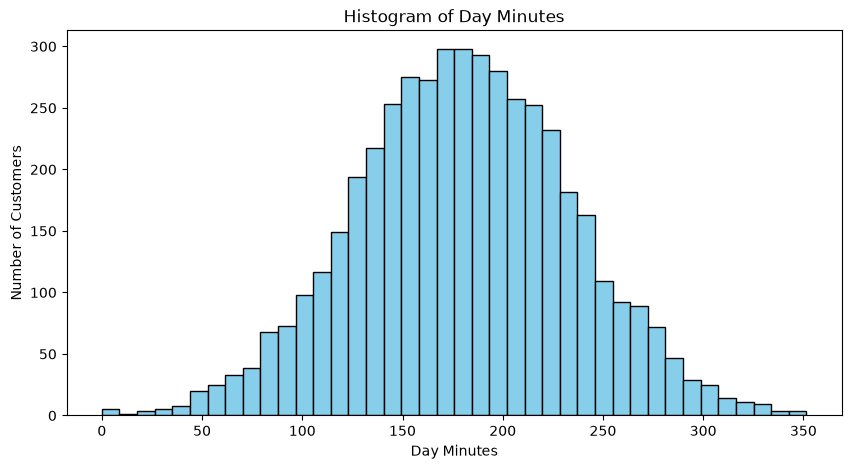

In [14]:
plt.figure(figsize=(10,5))
plt.hist(df['Day Mins'], bins=40, color='skyblue', edgecolor='black')
plt.title('Histogram of Day Minutes')
plt.xlabel('Day Minutes')
plt.ylabel('Number of Customers')
plt.show()

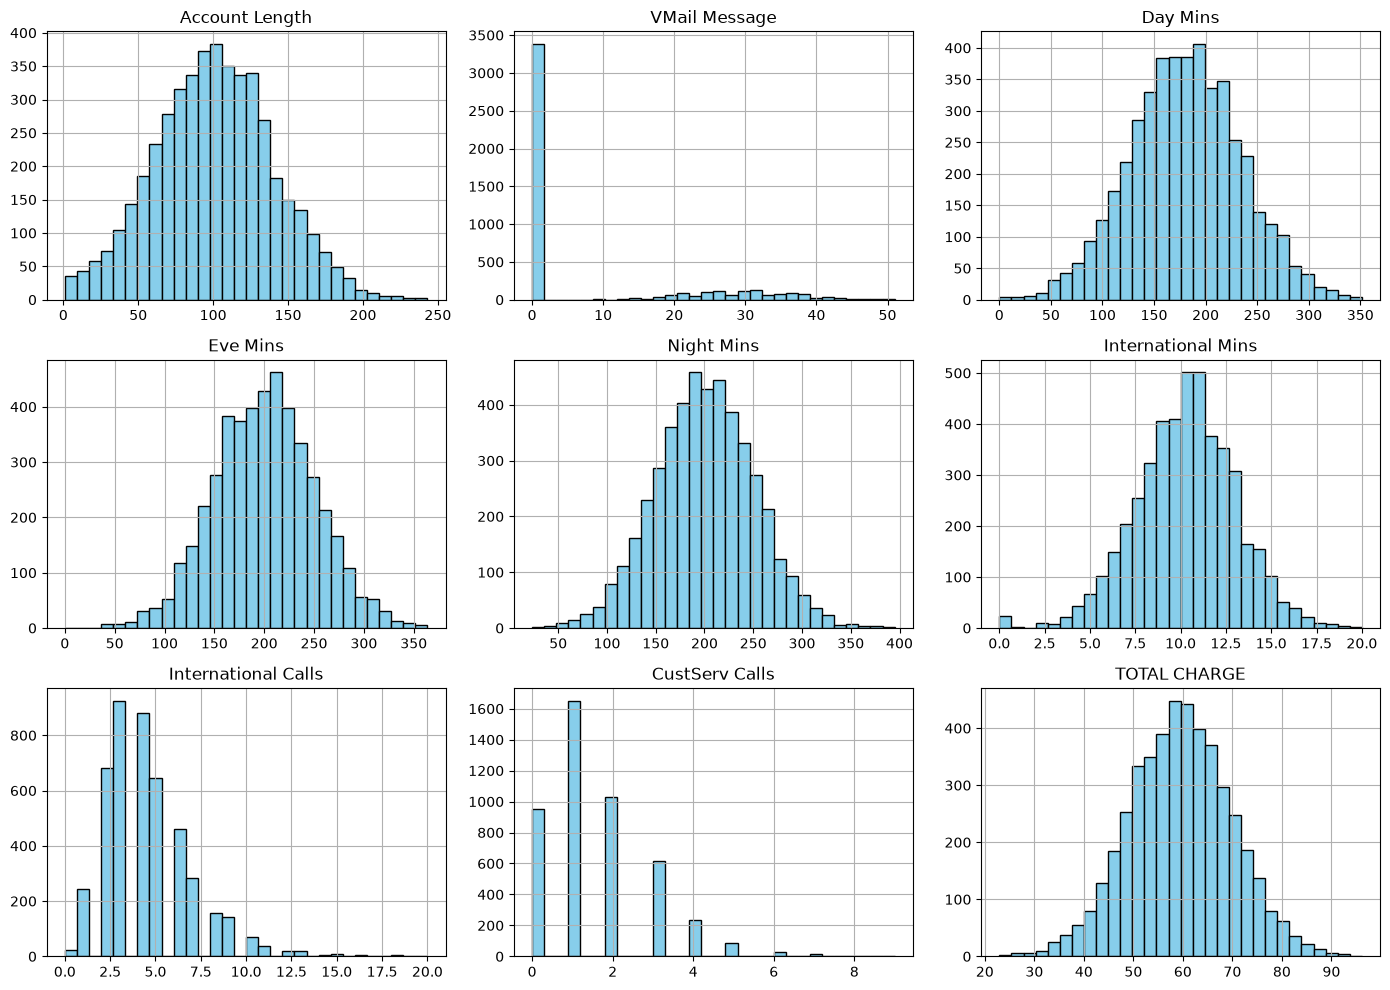

In [15]:
df[['Account Length', 'VMail Message', 'Day Mins', 'Eve Mins', 'Night Mins', 'International Mins',
    'International Calls', 'CustServ Calls', 'TOTAL CHARGE']].hist(figsize=(14,10), bins=30, color='skyblue', edgecolor='black')
plt.tight_layout()
plt.show()

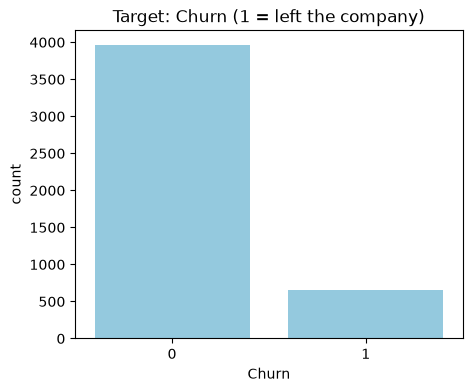

In [16]:
plt.figure(figsize=(5,4))
sns.countplot(data=df, x='Churn', color='skyblue')
plt.title('Target: Churn (1 = left the company)')
plt.show()

**Insights:** Day, evening and night minutes all have a **bell shape** (normal distribution) centred around 180-200 minutes, so most customers are average users and only a few are very light or very heavy. `CustServ Calls` is **right-skewed**: most customers call customer service 0-2 times, but a small group calls 4 to 9 times. `VMail Message` has a big spike at 0 (customers without the voice mail plan). The target is imbalanced: about 1 churner for every 6 customers who stay.

## 3. Relational Plots

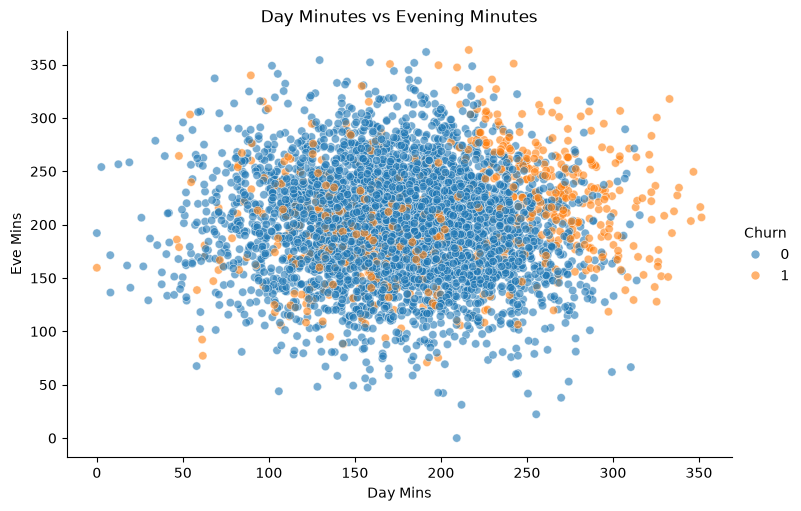

In [17]:
sns.relplot(data=df, x='Day Mins', y='Eve Mins', hue='Churn', height=5, aspect=1.5, alpha=0.6)
plt.title('Day Minutes vs Evening Minutes')
plt.show()

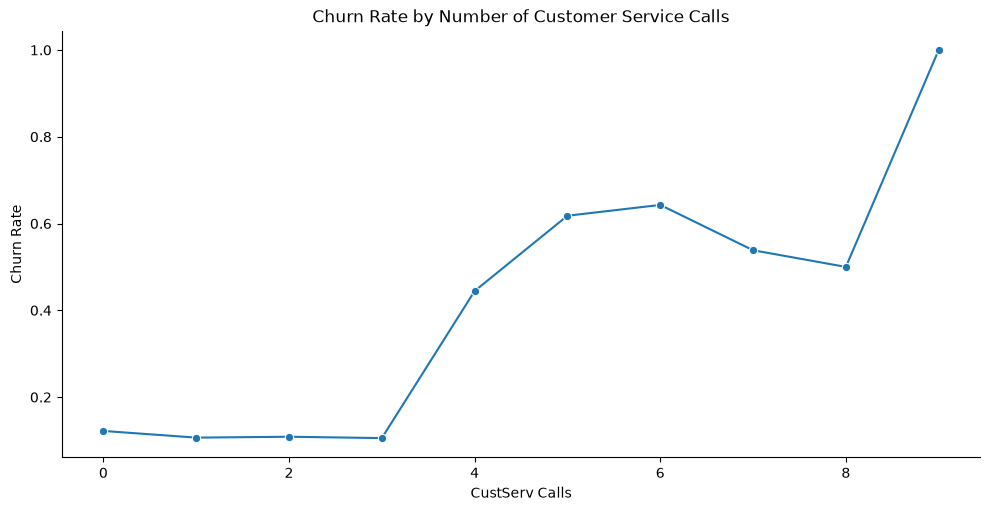

In [18]:
sns.relplot(data=df, x='CustServ Calls', y='Churn', kind='line', errorbar=None, marker='o', height=5, aspect=2)
plt.title('Churn Rate by Number of Customer Service Calls')
plt.ylabel('Churn Rate')
plt.show()

**Insights:**
- **Day vs evening minutes:** churners (orange) are concentrated in the **top-right corner**, where both day and evening use are high. The edge of that area runs **diagonally**, which means what matters is the **total bill**, not one type of call alone. This is the reason for creating `TOTAL CHARGE`.
- **Customer service calls:** the churn rate stays flat at about **11-12% for 0 to 3 calls**, then **jumps to 44% at 4 calls and over 60% at 5 or more calls**. The 4th call to customer service is a clear warning sign.

## 4. Pair Plot (Multivariate Analysis)

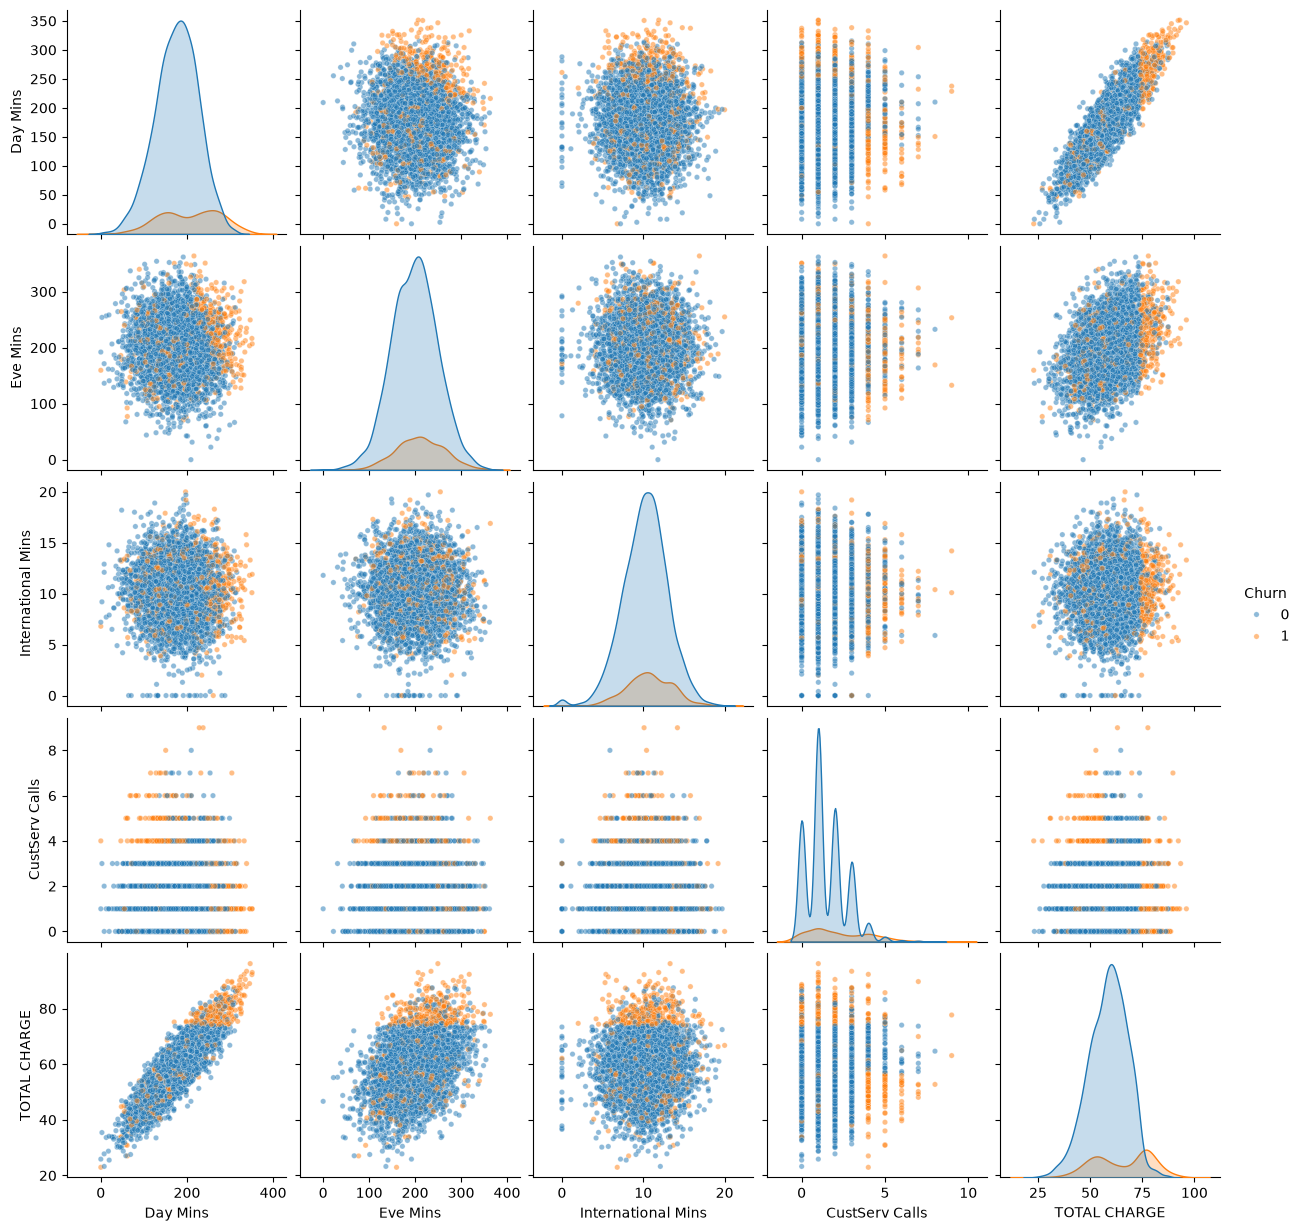

In [19]:
sns.pairplot(df[['Day Mins', 'Eve Mins', 'International Mins', 'CustServ Calls', 'TOTAL CHARGE', 'Churn']], hue='Churn',
             plot_kws={'alpha': 0.5, 's': 15})
plt.show()

**Insights:** The clearest separation is on **TOTAL CHARGE**: churners form a separate group at the high end of the bill. On **Day Mins** the churners also shift to the right, and in the `CustServ Calls` plots churners dominate from 4 calls upwards. In the combined plots (for example Day Mins vs CustServ Calls) the churners fall into **two separate groups**: high usage customers with few service calls, and normal usage customers with many service calls. So there are at least **two different reasons** for leaving. International minutes do not separate the classes on their own.

## 5. Data Preprocessing
### Boxplot

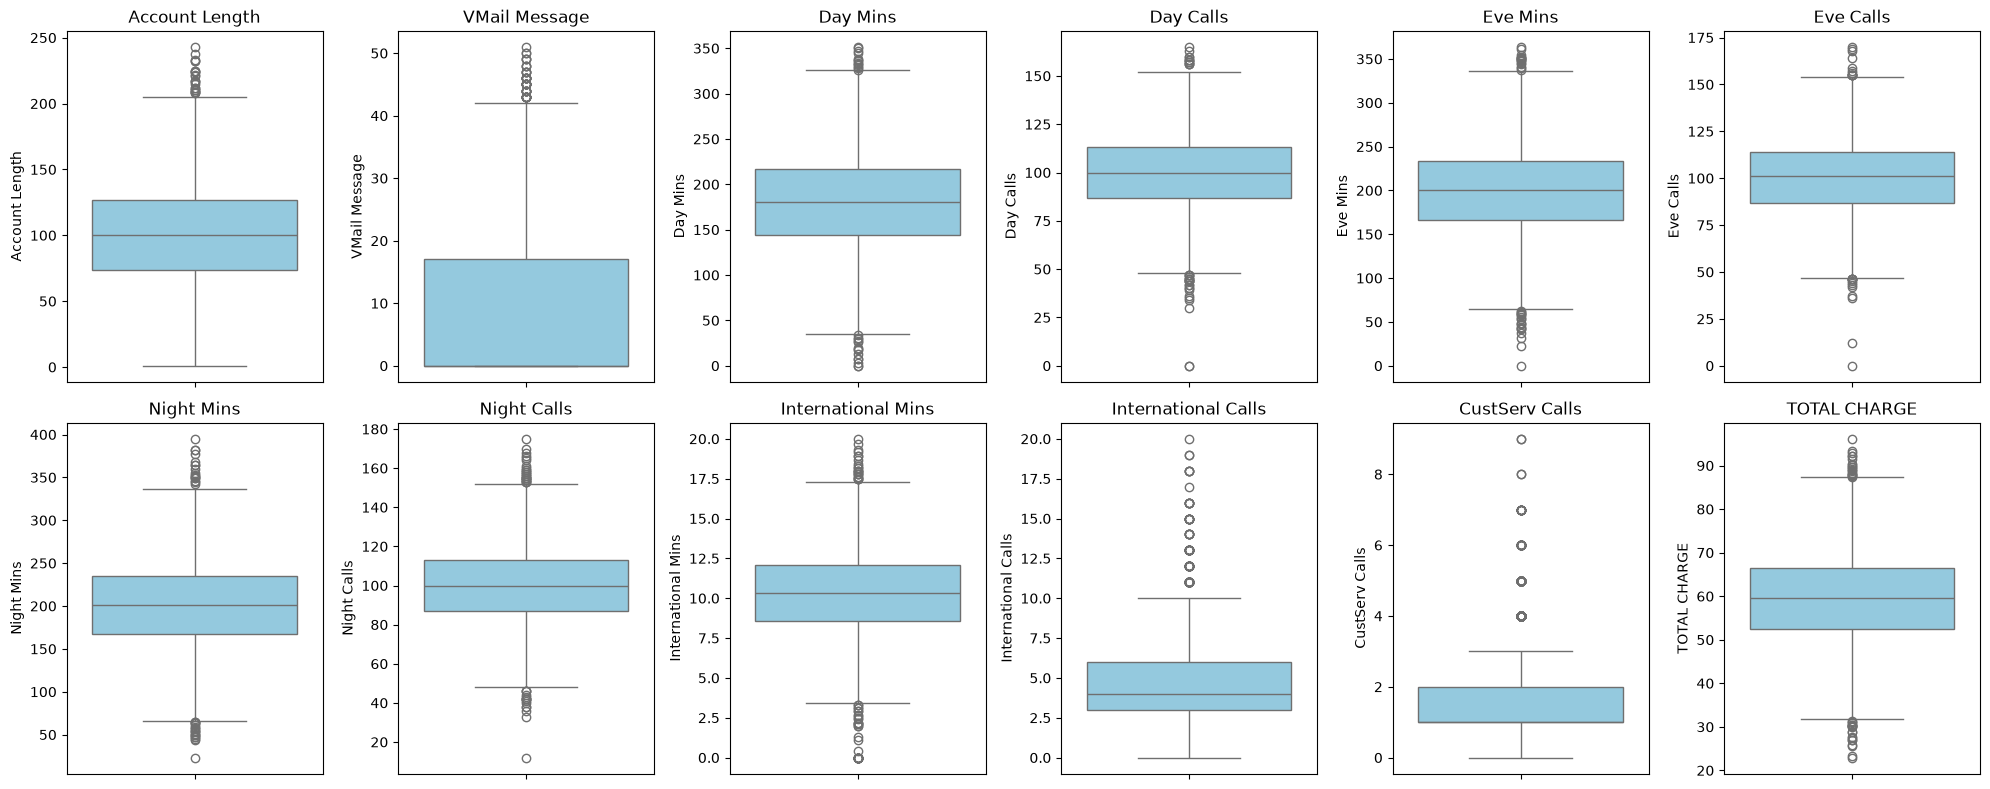

In [20]:
num_cols = ['Account Length', 'VMail Message', 'Day Mins', 'Day Calls', 'Eve Mins', 'Eve Calls', 'Night Mins',
            'Night Calls', 'International Mins', 'International Calls', 'CustServ Calls', 'TOTAL CHARGE']
fig, axes = plt.subplots(2, 6, figsize=(20,8))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

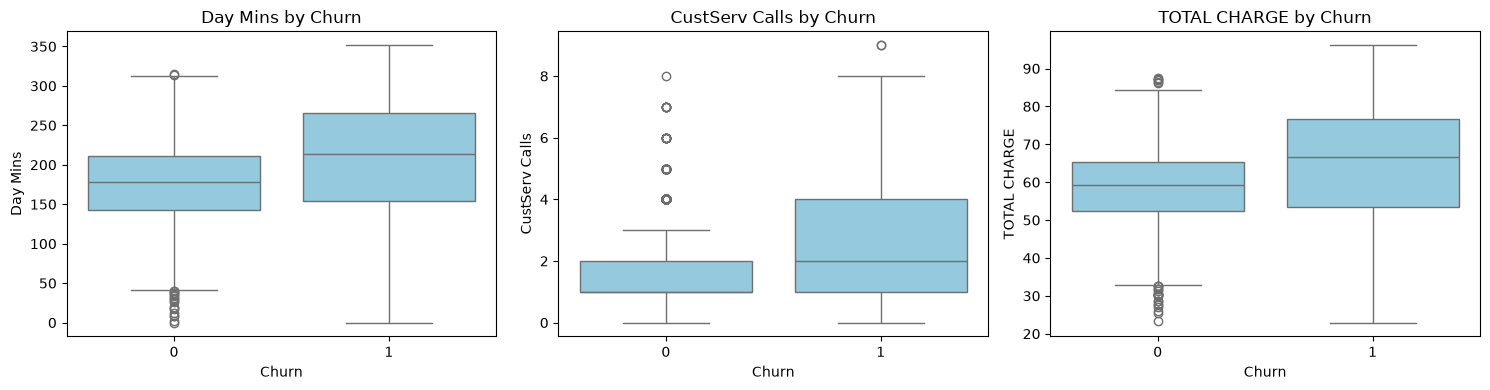

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, col in zip(axes, ['Day Mins', 'CustServ Calls', 'TOTAL CHARGE']):
    sns.boxplot(data=df, x='Churn', y=col, ax=ax, color='skyblue')
    ax.set_title(col + ' by Churn')
plt.tight_layout()
plt.show()

In [22]:
# find outliers with the IQR method
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    churn_out = df.loc[(df[col] < lower) | (df[col] > upper), 'Churn'].mean() * 100
    print(f'{col:20} | limits: {lower:7.1f} to {upper:7.1f} | outliers: {n_out:3} | churn rate of outliers: {churn_out:5.1f}%')

Account Length       | limits:    -5.5 to   206.5 | outliers:  23 | churn rate of outliers:  21.7%
VMail Message        | limits:   -25.5 to    42.5 | outliers:  51 | churn rate of outliers:   9.8%
Day Mins             | limits:    34.0 to   326.5 | outliers:  27 | churn rate of outliers:  51.9%
Day Calls            | limits:    48.0 to   152.0 | outliers:  34 | churn rate of outliers:  35.3%
Eve Mins             | limits:    63.8 to   336.1 | outliers:  36 | churn rate of outliers:  16.7%
Eve Calls            | limits:    46.5 to   154.5 | outliers:  25 | churn rate of outliers:   8.0%
Night Mins           | limits:    65.4 to   336.6 | outliers:  36 | churn rate of outliers:  13.9%
Night Calls          | limits:    48.0 to   152.0 | outliers:  42 | churn rate of outliers:  11.9%
International Mins   | limits:     3.3 to    17.4 | outliers:  65 | churn rate of outliers:  12.3%
International Calls  | limits:    -1.5 to    10.5 | outliers: 107 | churn rate of outliers:  16.8%
CustServ C

**Outliers**
- Most columns have only a few outliers (23 to 107 customers), and the values are all realistic (e.g. 0 day minutes for a customer who barely uses the phone, or 20 international calls).
- The outliers are **not errors, they are the most useful customers to study**: the churn rate is **50.8% for the 368 customers with 4+ service calls**, **51.9% for the 27 customers with extreme Day Mins** and **57.9% for the 38 customers with extreme TOTAL CHARGE**, against 14.2% on average.
- Removing or capping them would delete exactly the customers the company needs to find, so **all outliers are kept**. The models used later are tree based and are not thrown off by extreme values.

### Line Plot

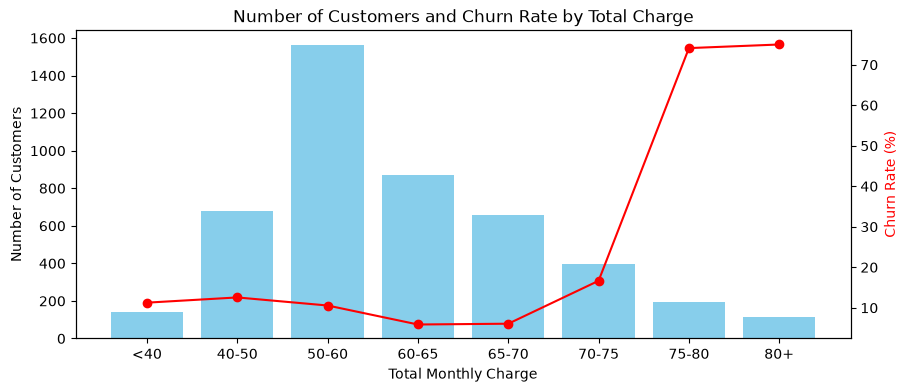

In [23]:
by_charge = df.groupby('CHARGE GROUP').agg(customers=('Churn', 'count'), rate=('Churn', 'mean'))

fig, ax1 = plt.subplots(figsize=(10,4))
ax1.bar(by_charge.index.astype(str), by_charge['customers'], color='skyblue', label='Number of customers')
ax1.set_ylabel('Number of Customers')
ax1.set_xlabel('Total Monthly Charge')
ax2 = ax1.twinx()
ax2.plot(by_charge.index.astype(str), by_charge['rate'] * 100, marker='o', color='red', label='Churn rate')
ax2.set_ylabel('Churn Rate (%)', color='red')
plt.title('Number of Customers and Churn Rate by Total Charge')
plt.show()

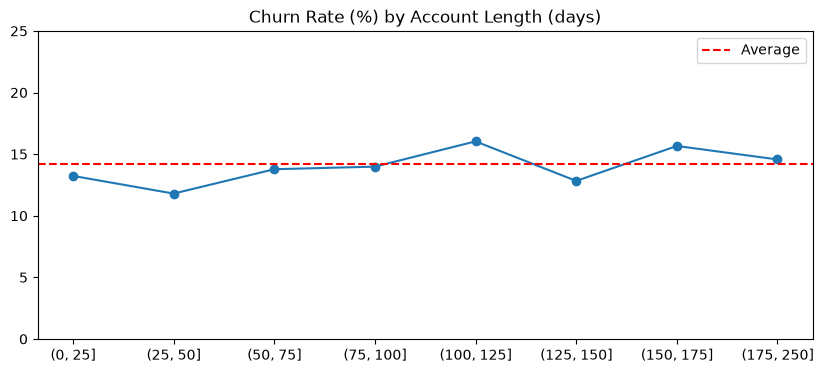

In [24]:
df['ACCOUNT GROUP'] = pd.cut(df['Account Length'], bins=[0, 25, 50, 75, 100, 125, 150, 175, 250])
rate = df.groupby('ACCOUNT GROUP')['Churn'].mean() * 100
plt.figure(figsize=(10,4))
plt.plot(rate.index.astype(str), rate.values, marker='o')
plt.axhline(df['Churn'].mean() * 100, color='red', linestyle='--', label='Average')
plt.title('Churn Rate (%) by Account Length (days)')
plt.ylim(0, 25)
plt.legend()
plt.show()

**Insights:**
- **Total charge** has a sharp turning point. Below a bill of 75 the churn rate is between 6% and 17% (lowest, about 6%, for bills of 60-70). **Above 75 it jumps to 74-75%**. Only 313 customers (6.8%) have a bill above 75, but they make up about a third of all churners.
- **Account length** (how long the customer has been with the company) makes almost no difference: the churn rate stays between 12% and 16% for every group. New customers are not more likely to leave than old ones.

### Barplot

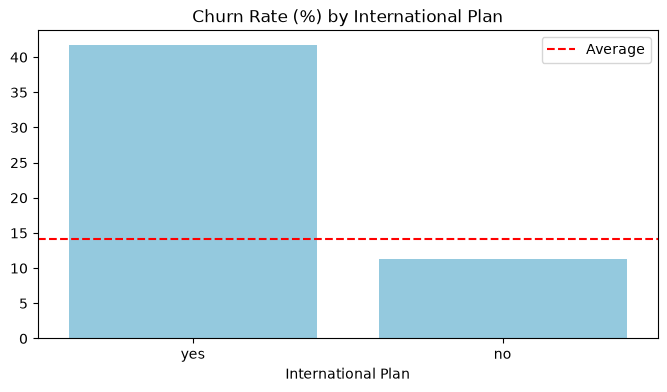

In [25]:
def rate_plot(col, order=None, figsize=(8,4)):
    rate = df.groupby(col)['Churn'].mean().mul(100)
    rate = rate.reindex(order) if order else rate.sort_values(ascending=False)
    plt.figure(figsize=figsize)
    sns.barplot(x=rate.index.astype(str), y=rate.values, color='skyblue')
    plt.axhline(df['Churn'].mean() * 100, color='red', linestyle='--', label='Average')
    plt.title('Churn Rate (%) by ' + col)
    plt.xticks(rotation=45 if len(rate) > 10 else 0)
    plt.legend()
    plt.show()

rate_plot('International Plan')

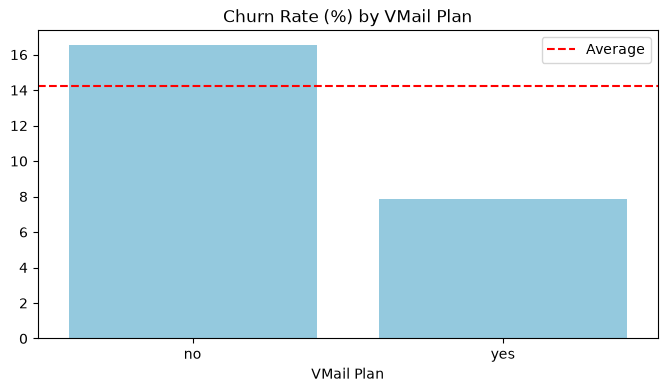

In [26]:
rate_plot('VMail Plan')

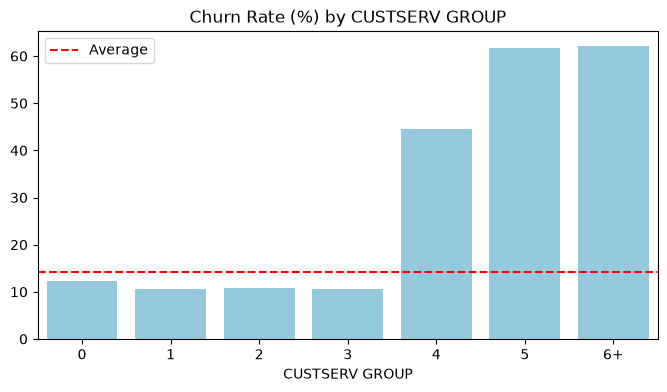

In [27]:
rate_plot('CUSTSERV GROUP', ['0', '1', '2', '3', '4', '5', '6+'])

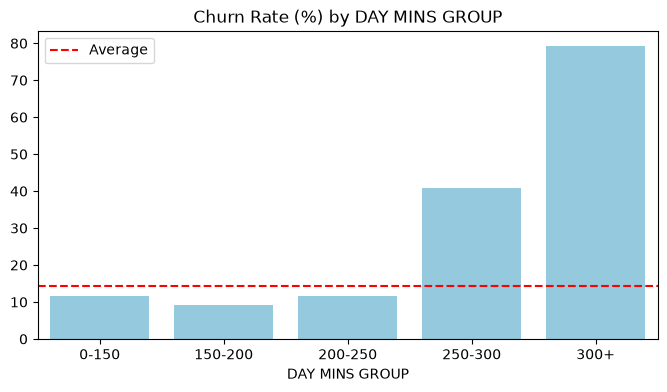

In [28]:
rate_plot('DAY MINS GROUP', ['0-150', '150-200', '200-250', '250-300', '300+'])

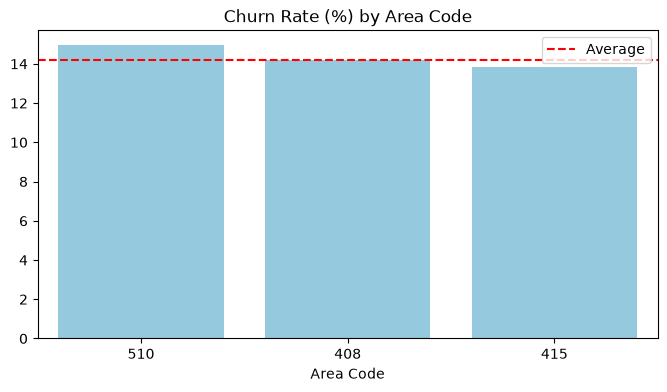

In [29]:
rate_plot('Area Code')

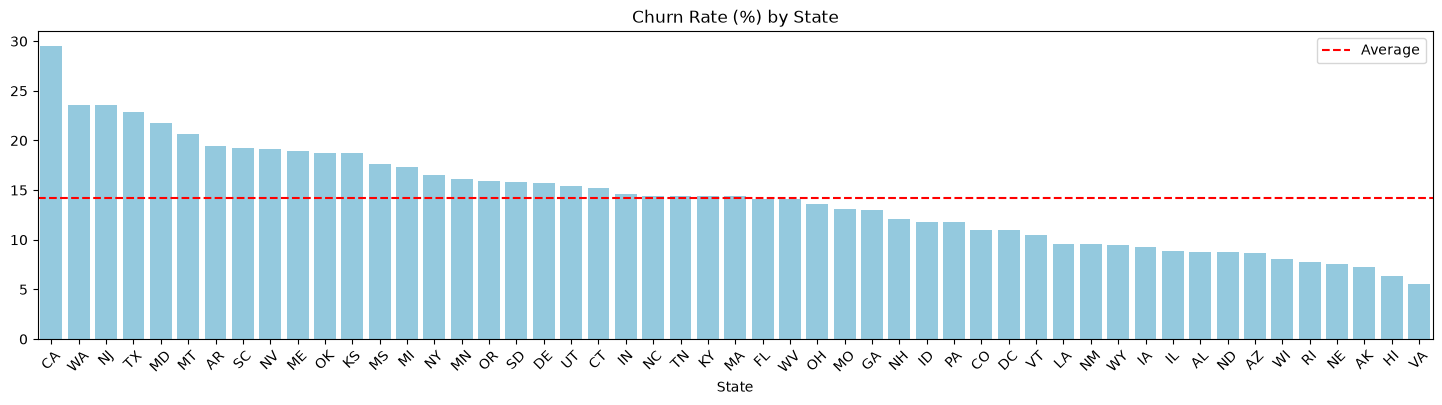

In [30]:
rate_plot('State', figsize=(18,4))

In [31]:
# group sizes behind the bars
for col in ['International Plan', 'VMail Plan', 'CUSTSERV GROUP', 'DAY MINS GROUP', 'Area Code']:
    print(df.groupby(col).agg(customers=('Churn', 'count'), churn_pct=('Churn', 'mean'))
          .assign(churn_pct=lambda t: (t.churn_pct * 100).round(1)), '\n')

                    customers  churn_pct
International Plan                      
no                       4171       11.3
yes                       446       41.7 

            customers  churn_pct
VMail Plan                      
no               3381       16.5
yes              1236        7.8 

                customers  churn_pct
CUSTSERV GROUP                      
0                     951       12.2
1                    1651       10.7
2                    1031       10.9
3                     616       10.6
4                     234       44.4
5                      89       61.8
6+                     45       62.2 

                customers  churn_pct
DAY MINS GROUP                      
0-150                1334       11.6
150-200              1635        9.2
200-250              1193       11.7
250-300               392       40.8
300+                   63       79.4 

           customers  churn_pct
Area Code                      
408             1161       14.2
415     

In [32]:
# is the difference between states / area codes real or just chance? (chi-square test)
from scipy.stats import chi2_contingency
for col in ['State', 'Area Code', 'International Plan', 'VMail Plan']:
    p = chi2_contingency(pd.crosstab(df[col], df['Churn']))[1]
    print(f'{col:20} p-value = {p:.6f}')
print('\nCustomers per state: min', df['State'].value_counts().min(), '| max', df['State'].value_counts().max())

State                p-value = 0.000372
Area Code            p-value = 0.672816
International Plan   p-value = 0.000000
VMail Plan           p-value = 0.000000

Customers per state: min 44 | max 149


**Insights** (red line = average churn rate of 14.2%)
- **International Plan:** **41.7% churn with the plan vs 11.3% without** (446 customers have the plan). Customers who pay for the international plan are almost 4 times more likely to leave.
- **Voice Mail Plan:** customers **with** the plan churn **less** (7.8% vs 16.5%).
- **Customer service calls:** about 11% for 0-3 calls, **44.4% at 4 calls, 61.8% at 5 and 62.2% at 6+**.
- **Day minutes:** 9-12% up to 250 minutes, then **40.8% for 250-300 and 79.4% above 300**.
- **Area Code:** 13.8% to 15.0%, no real difference (chi-square p-value 0.67).
- **State:** ranges from **5.5% (VA) to 29.5% (CA)**. The chi-square test says the difference between states is unlikely to be pure chance (p = 0.0004), but each state has only 44-149 customers, so a few churners move a state's rate a lot (e.g. CA has only 44 customers). The state is useful for reporting, but it is a weak base for decisions.

### Label Encoding
`State`, `International Plan` and `VMail Plan` are text, so they are converted into numbers with `LabelEncoder` (for the plans: no = 0, yes = 1).

In [33]:
from sklearn.preprocessing import LabelEncoder

data = df.drop(columns=['CUSTSERV GROUP', 'DAY MINS GROUP', 'CHARGE GROUP', 'ACCOUNT GROUP']).copy()
le = LabelEncoder()
for col in ['State', 'International Plan', 'VMail Plan']:
    data[col] = le.fit_transform(data[col])
data.head()

,State,Account Length,Area Code,International Plan,VMail Plan,VMail Message,Day Mins,Day Calls,Day Charge,Eve Mins,Eve Calls,Eve Charge,Night Mins,Night Calls,Night Charge,International Mins,International Calls,International Charge,CustServ Calls,Churn,TOTAL MINS,TOTAL CALLS,TOTAL CHARGE
0,16,128,415,0,1,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0,717.2,303,75.56
1,35,107,415,0,1,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0,625.2,332,59.24
2,31,137,415,0,0,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0,539.4,333,62.29
3,35,84,408,1,0,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0,564.8,255,66.80
4,36,75,415,1,0,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0,512.0,359,52.09


## 6. Feature Selection & Heat Map

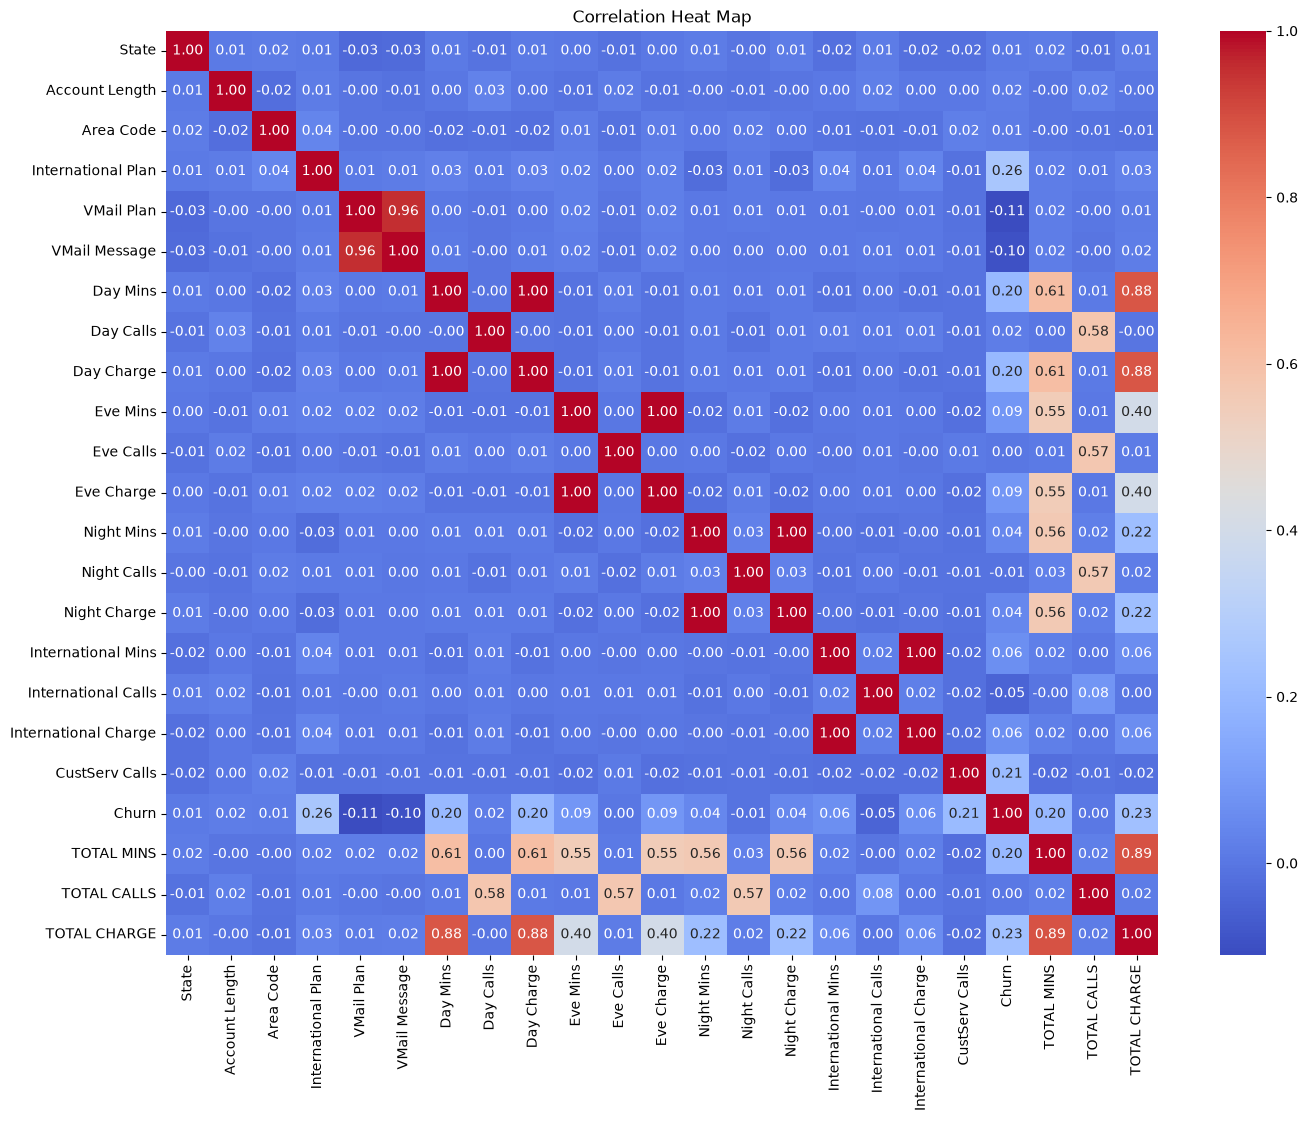

In [34]:
plt.figure(figsize=(16,12))
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heat Map')
plt.show()

In [35]:
data.corr()['Churn'].drop('Churn').sort_values(ascending=False)

International Plan      0.257524
TOTAL CHARGE            0.229438
CustServ Calls          0.209351
Day Mins                0.202439
Day Charge              0.202434
TOTAL MINS              0.198725
Eve Mins                0.087042
Eve Charge              0.087036
International Mins      0.064731
International Charge    0.064728
Night Mins              0.043262
Night Charge            0.043260
Account Length          0.018046
Day Calls               0.016268
Area Code               0.011995
State                   0.010979
TOTAL CALLS             0.003395
Eve Calls               0.001943
Night Calls            -0.006671
International Calls    -0.045844
VMail Message          -0.096884
VMail Plan             -0.110149
Name: Churn, dtype: float64

**Feature selection**
- **Charge columns dropped** (`Day Charge`, `Eve Charge`, `Night Charge`, `International Charge`): correlation **1.00** with their Minutes columns, so they add no new information. Their combined effect is kept in `TOTAL CHARGE`.
- **TOTAL MINS dropped:** correlation 0.89 with `TOTAL CHARGE`, and `TOTAL CHARGE` has the stronger link with churn (0.23 vs 0.20), because the bill weights day minutes (the most expensive) the most.
- **Area Code dropped:** no relation with churn (correlation 0.01, chi-square p = 0.67).
- **State dropped:** after label encoding, the numbers 0-50 are just alphabetical order, which means nothing to a model. With only 44-149 customers per state the model would mostly memorise noise. When it was tested, adding State did not improve the score.
- **Strongest links with churn:** International Plan (0.26), TOTAL CHARGE (0.23), CustServ Calls (0.21) and Day Mins (0.20). VMail Plan (-0.11) lowers churn.
- Some features (like `Day Calls` or `Account Length`) have almost zero correlation but are kept, because correlation only measures straight-line relations and the tree models can find other patterns. The model itself will show which ones matter.
- **15 features are used:** Account Length, International Plan, VMail Plan, VMail Message, Day/Eve/Night Mins and Calls, International Mins and Calls, CustServ Calls, TOTAL CHARGE and TOTAL CALLS.

# Part 2: Predictive Model

## Which algorithm suits this data best?
We want to predict whether a customer will **churn (yes / no)**, so this is a **supervised binary classification** problem. We also need a **probability** for each customer, which becomes the **Churn Risk Score**.
- Linear Regression is for numbers, not yes/no answers, so it doesn't fit.
- K-Means and PCA are unsupervised, so they don't fit.
- Logistic Regression, Decision Tree, KNN, Random Forest and Gradient Boosting can all do classification and give probabilities, so we try all five and compare them.

**Important:** only 14.2% of customers churn. A model that always says "no churn" would be 86% accurate and completely useless. So we judge the models on **ROC-AUC** (how well they rank churners above non-churners), **recall** (how many real churners we find) and **F1**, not on accuracy.

**Expected Best: Gradient Boosting or Random Forest**, because the patterns are non-linear: churn is flat up to 3 service calls and then jumps, and it is flat up to a bill of 75 and then jumps. Straight-line models like Logistic Regression can't draw these sharp steps.

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

features = ['Account Length', 'International Plan', 'VMail Plan', 'VMail Message', 'Day Mins', 'Day Calls',
            'Eve Mins', 'Eve Calls', 'Night Mins', 'Night Calls', 'International Mins', 'International Calls',
            'CustServ Calls', 'TOTAL CHARGE', 'TOTAL CALLS']
X = data[features]
y = data['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# scale the features (needed for Logistic Regression and KNN, does not change tree models)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(X_train.shape, X_test.shape)
print('Percent churn in train:', round(y_train.mean() * 100, 1), '| in test:', round(y_test.mean() * 100, 1))

(3693, 15) (924, 15)
Percent churn in train: 14.2 | in test: 14.2


In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# class_weight='balanced' makes the models pay more attention to the small 'churn' class
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', max_depth=6, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=15),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', max_depth=10,
                                            min_samples_leaf=3, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}

rows = []
for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    prob = model.predict_proba(X_test_s)[:, 1]
    rows.append([name, roc_auc_score(y_train, model.predict_proba(X_train_s)[:, 1]), roc_auc_score(y_test, prob),
                 accuracy_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred), f1_score(y_test, pred)])

results = pd.DataFrame(rows, columns=['Model', 'Train AUC', 'Test AUC', 'Accuracy', 'Precision', 'Recall', 'F1']).round(3)
results.sort_values('Test AUC', ascending=False)

,Model,Train AUC,Test AUC,Accuracy,Precision,Recall,F1
4,Gradient Boosting,0.988,0.920,0.976,0.958,0.870,0.912
3,Random Forest,0.999,0.914,0.977,0.966,0.870,0.916
1,Decision Tree,0.961,0.911,0.970,0.933,0.847,0.888
2,KNN,0.946,0.882,0.893,0.848,0.298,0.441
0,Logistic Regression,0.833,0.812,0.774,0.360,0.763,0.489


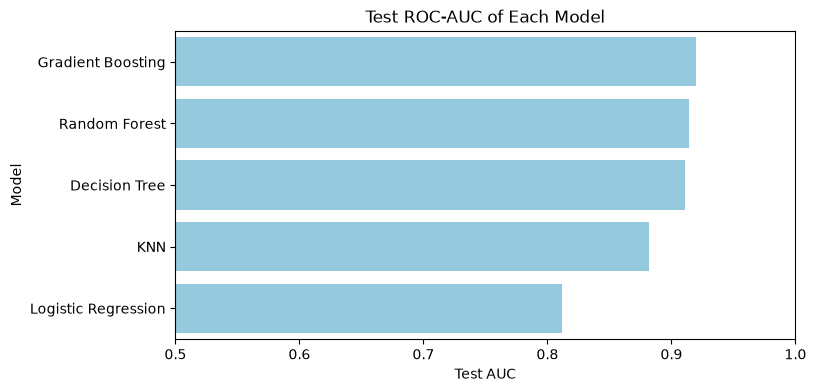

In [38]:
plt.figure(figsize=(8,4))
sns.barplot(data=results.sort_values('Test AUC', ascending=False), x='Test AUC', y='Model', color='skyblue')
plt.title('Test ROC-AUC of Each Model')
plt.xlim(0.5, 1)
plt.show()

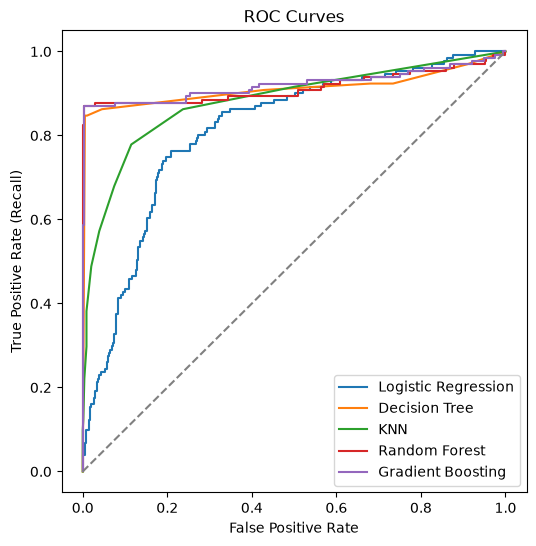

In [39]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(6,6))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test_s)[:, 1])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], color='grey', linestyle='--')
plt.title('ROC Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend()
plt.show()

**Insights:** **Gradient Boosting (test AUC 0.920), Random Forest (0.914) and Decision Tree (0.911)** are clearly ahead. They find about **85-87% of the churners**, and when they say "churn" they are right **93-97%** of the time. **Logistic Regression is the weakest (0.812)**, as expected, because it can only draw straight lines and the churn pattern has sharp steps. **KNN** has a decent AUC (0.882) but finds only **30% of the churners**. Random Forest and Gradient Boosting have a train AUC close to 1.0, which means they fit the training data very closely, but their test score is still the best, so they generalise well.

### Cross-validation check
One test split of 924 customers has only 131 churners, so a few customers can move the score. We check the models with **5-fold cross-validation**: the data is split 5 different ways and each model is trained and tested 5 times.

In [40]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

cv_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000)),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', max_depth=6, random_state=42),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', max_depth=10,
                                            min_samples_leaf=3, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, model in cv_models.items():
    s = cross_validate(model, X, y, cv=cv5, scoring=['roc_auc', 'recall', 'precision', 'f1'])
    rows.append([name, s['test_roc_auc'].mean(), s['test_roc_auc'].std(), s['test_recall'].mean(),
                 s['test_precision'].mean(), s['test_f1'].mean()])
cv_results = pd.DataFrame(rows, columns=['Model', 'CV AUC (mean)', 'CV AUC (std)', 'CV Recall', 'CV Precision', 'CV F1']).round(3)
cv_results.sort_values('CV AUC (mean)', ascending=False)

,Model,CV AUC (mean),CV AUC (std),CV Recall,CV Precision,CV F1
4,Gradient Boosting,0.923,0.015,0.860,0.979,0.915
3,Random Forest,0.918,0.015,0.860,0.993,0.921
1,Decision Tree,0.916,0.024,0.849,0.946,0.895
2,KNN,0.886,0.008,0.280,0.909,0.428
0,Logistic Regression,0.824,0.015,0.768,0.357,0.487


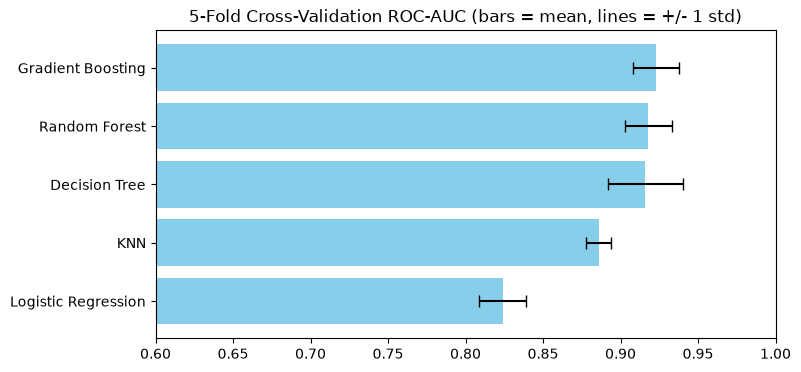

In [41]:
cv_sorted = cv_results.sort_values('CV AUC (mean)')
plt.figure(figsize=(8,4))
plt.barh(cv_sorted['Model'], cv_sorted['CV AUC (mean)'], xerr=cv_sorted['CV AUC (std)'], color='skyblue', capsize=4)
plt.title('5-Fold Cross-Validation ROC-AUC (bars = mean, lines = +/- 1 std)')
plt.xlim(0.6, 1)
plt.show()

**Cross-validation result:** Gradient Boosting (0.923), Random Forest (0.918) and Decision Tree (0.916) are **very close**. The differences between them (0.005 or less) are smaller than how much each score moves from one split to another (std about 0.015-0.024), so they are practically tied. KNN (0.886) and Logistic Regression (0.824) are clearly behind in every fold. The cross-validated scores agree with the single test split, so about **0.92 is an honest estimate** for new customers.

## Hyperparameter Tuning
So far the models used hand-picked settings. Here we search for better settings in a structured way:
1. **GridSearchCV** on Random Forest: try every combination of `n_estimators` and `max_depth`.
2. **RandomizedSearchCV** on Random Forest: try 20 random combinations from a wider range of settings.
3. **RandomizedSearchCV** on **HistGradientBoosting**, a faster version of Gradient Boosting. Boosting builds trees one after another, each fixing the mistakes of the previous ones, unlike Random Forest which builds independent trees and averages them.

All searches use **only the training data** with 3-fold cross-validation and are scored on ROC-AUC. The test set is kept aside for the final comparison.

In [42]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import HistGradientBoostingClassifier
from scipy.stats import randint, loguniform

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 1. Grid search: n_estimators x max_depth
rf_grid = GridSearchCV(RandomForestClassifier(class_weight='balanced', min_samples_leaf=3, random_state=42, n_jobs=-1),
                       param_grid={'n_estimators': [100, 300, 500], 'max_depth': [4, 6, 8, 10, 12, 15, None]},
                       scoring='roc_auc', cv=cv3)
rf_grid.fit(X_train, y_train)
print('Best settings :', rf_grid.best_params_)
print('Best CV AUC   :', round(rf_grid.best_score_, 4))

Best settings : {'max_depth': 4, 'n_estimators': 300}
Best CV AUC   : 0.9267


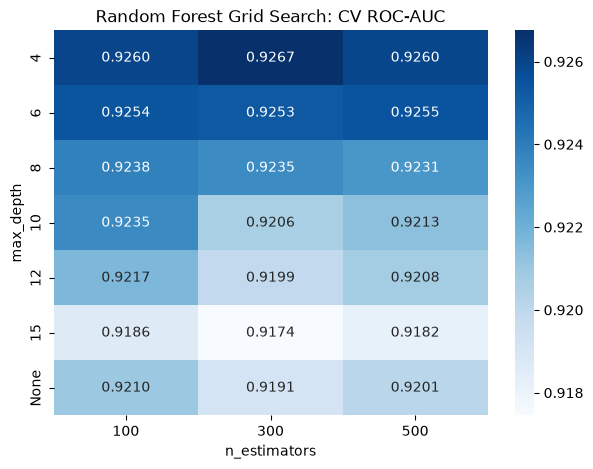

In [43]:
grid_table = pd.DataFrame(rf_grid.cv_results_)
grid_table['max_depth'] = grid_table['param_max_depth'].apply(lambda d: 'None' if pd.isna(d) else str(int(d)))   # so that None is shown too
grid_table = grid_table.pivot_table(index='max_depth', columns='param_n_estimators', values='mean_test_score')
grid_table = grid_table.reindex(['4', '6', '8', '10', '12', '15', 'None'])

plt.figure(figsize=(7,5))
sns.heatmap(grid_table, annot=True, fmt='.4f', cmap='Blues')
plt.title('Random Forest Grid Search: CV ROC-AUC')
plt.xlabel('n_estimators')
plt.show()

In [44]:
# 2. Randomized search on Random Forest (wider range of settings)
rf_random = RandomizedSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                               param_distributions={'n_estimators': randint(200, 600),
                                                    'max_depth': randint(5, 20),
                                                    'min_samples_leaf': randint(1, 20),
                                                    'max_features': ['sqrt', 'log2', 0.5, 0.8],
                                                    'class_weight': ['balanced', 'balanced_subsample', None]},
                               n_iter=20, scoring='roc_auc', cv=cv3, random_state=42)
rf_random.fit(X_train, y_train)
print('Best settings :', rf_random.best_params_)
print('Best CV AUC   :', round(rf_random.best_score_, 4))

Best settings : {'class_weight': 'balanced_subsample', 'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 1, 'n_estimators': 513}
Best CV AUC   : 0.9243


In [45]:
# 3. Randomized search on HistGradientBoosting
hgb_random = RandomizedSearchCV(HistGradientBoostingClassifier(random_state=42, early_stopping=False),
                                param_distributions={'learning_rate': loguniform(0.01, 0.2),
                                                     'max_iter': randint(100, 600),
                                                     'max_depth': [3, 4, 5, 6, 8, None],
                                                     'max_leaf_nodes': randint(8, 48),
                                                     'min_samples_leaf': randint(5, 60),
                                                     'l2_regularization': loguniform(0.001, 10),
                                                     'class_weight': [None, 'balanced']},
                                n_iter=30, scoring='roc_auc', cv=cv3, random_state=42)
hgb_random.fit(X_train, y_train)
print('Best settings :', hgb_random.best_params_)
print('Best CV AUC   :', round(hgb_random.best_score_, 4))

Best settings : {'class_weight': 'balanced', 'l2_regularization': np.float64(0.008789004341405478), 'learning_rate': np.float64(0.021535381457547638), 'max_depth': 5, 'max_iter': 492, 'max_leaf_nodes': 22, 'min_samples_leaf': 19}
Best CV AUC   : 0.9237


## Ensembles Beyond Bagging
Random Forest is a **bagging** ensemble (many trees on random samples, averaged). We also try two ways of combining *different kinds* of models:
- **Soft Voting:** average the predicted probabilities of the tuned Random Forest, the tuned HistGradientBoosting and Gradient Boosting.
- **Stacking:** the same base models (plus Logistic Regression) make predictions, and a Logistic Regression **meta-model** learns how much to trust each one.

In [46]:
from sklearn.ensemble import VotingClassifier, StackingClassifier

lr_pipe = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000))

voting = VotingClassifier([('rf', rf_random.best_estimator_), ('hgb', hgb_random.best_estimator_),
                           ('gb', GradientBoostingClassifier(random_state=42))], voting='soft')
voting.fit(X_train, y_train)

stacking = StackingClassifier([('rf', rf_random.best_estimator_), ('hgb', hgb_random.best_estimator_),
                               ('gb', GradientBoostingClassifier(random_state=42)), ('lr', lr_pipe)],
                              final_estimator=LogisticRegression(max_iter=1000),
                              cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
stacking.fit(X_train, y_train)
print('done')

done


### Comparing the tuned models and ensembles
We compare them on the **test set** and with **5-fold cross-validation** on the full data. Besides ROC-AUC we show **PR-AUC** (how well the churners are found) and the share of all churners reached by contacting only the **top 20%** of customers ranked by the model, which is how the retention team would actually use the risk score.

In [47]:
from sklearn.metrics import average_precision_score
from sklearn.base import clone

def top20_capture(y_true, prob):
    order = np.argsort(-prob)
    top = np.asarray(y_true)[order][:int(len(prob) * 0.2)]
    return top.sum() / np.sum(y_true)

final_models = {
    'Random Forest (hand-picked)': cv_models['Random Forest'],
    'Gradient Boosting (default)': cv_models['Gradient Boosting'],
    'Random Forest (grid search)': rf_grid.best_estimator_,
    'Random Forest (random search)': rf_random.best_estimator_,
    'HistGradientBoosting (random search)': hgb_random.best_estimator_,
    'Soft Voting': voting,
    'Stacking': stacking,
}

rows = []
for name, model in final_models.items():
    m = clone(model).fit(X_train, y_train)
    prob = m.predict_proba(X_test)[:, 1]
    pred = m.predict(X_test)
    cv_auc = cross_validate(clone(model), X, y, cv=cv5, scoring='roc_auc')['test_score']
    rows.append([name, roc_auc_score(y_test, prob), average_precision_score(y_test, prob), recall_score(y_test, pred),
                 precision_score(y_test, pred), f1_score(y_test, pred), top20_capture(y_test, prob), cv_auc.mean(), cv_auc.std()])

tuned = pd.DataFrame(rows, columns=['Model', 'Test AUC', 'Test PR-AUC', 'Recall', 'Precision', 'F1',
                                    'Churners in top 20%', 'CV AUC (mean)', 'CV AUC (std)']).round(3)
tuned.sort_values('CV AUC (mean)', ascending=False)

,Model,Test AUC,Test PR-AUC,Recall,Precision,F1,Churners in top 20%,CV AUC (mean),CV AUC (std)
4,HistGradientBoosting (random search),0.946,0.917,0.863,0.974,0.915,0.885,0.925,0.019
2,Random Forest (grid search),0.912,0.894,0.878,0.782,0.827,0.878,0.924,0.011
1,Gradient Boosting (default),0.920,0.893,0.870,0.958,0.912,0.878,0.923,0.015
3,Random Forest (random search),0.918,0.900,0.840,0.982,0.905,0.878,0.921,0.016
5,Soft Voting,0.930,0.911,0.870,0.991,0.927,0.893,0.920,0.020
6,Stacking,0.930,0.911,0.870,0.974,0.919,0.893,0.920,0.019
0,Random Forest (hand-picked),0.915,0.899,0.870,0.966,0.916,0.878,0.918,0.015


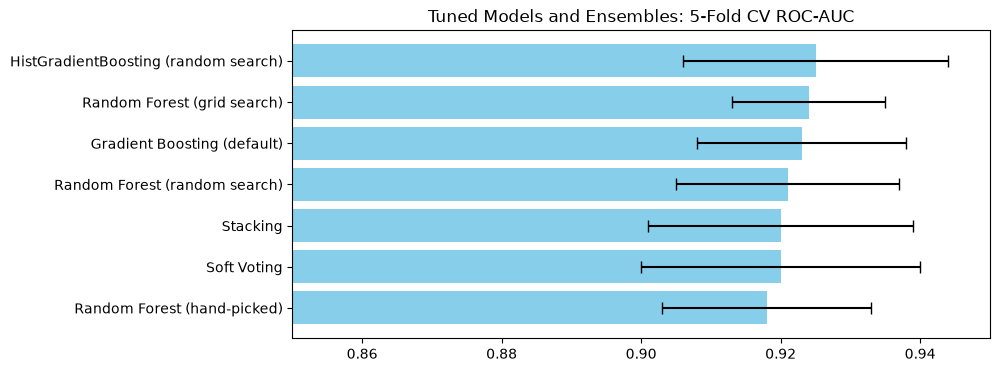

In [48]:
tuned_sorted = tuned.sort_values('CV AUC (mean)')
plt.figure(figsize=(9,4))
plt.barh(tuned_sorted['Model'], tuned_sorted['CV AUC (mean)'], xerr=tuned_sorted['CV AUC (std)'], color='skyblue', capsize=4)
plt.title('Tuned Models and Ensembles: 5-Fold CV ROC-AUC')
plt.xlim(0.85, 0.95)
plt.show()

**Tuning result**

**What the grid search showed (`n_estimators` x `max_depth`):**
- **Shallow trees work best.** The best depth is **4** (CV AUC 0.927). The score drops steadily as the trees get deeper: depth 8 gives 0.924, depth 15 gives 0.918. Deep trees start **memorising the training data** (overfitting), and the churn rules are simple (a few thresholds on bill, service calls and plans), so shallow trees are enough.
- The number of trees makes almost no difference (less than 0.001 between 100 and 500 trees).

**What the randomized searches found:**
- **Random Forest** (20 combinations): best was depth 10, `max_features='log2'`, `class_weight='balanced_subsample'`, 513 trees, CV AUC 0.924 on the training data.
- **HistGradientBoosting** (30 combinations): best was a slow learning rate (0.022) with 492 trees of depth 5 and `class_weight='balanced'`, CV AUC 0.924 on the training data.

**Final comparison (table above):**
- All tuned models and ensembles are between **0.918 and 0.925 CV AUC**, so tuning moved the score by less than 0.01. The data itself, not the algorithm, limits the score to about 0.92.
- **HistGradientBoosting (random search)** has the best cross-validated AUC (**0.925**) and the best test AUC (**0.946**), with **97.4% precision** and **86.3% recall**.
- **Soft Voting and Stacking** were not better than the best single model (0.920 CV AUC). They combine models that make the **same mistakes** (all of them miss the same churners), so averaging them does not help.
- The grid-search Random Forest has a lower precision (78%) because shallow trees with balanced class weights mark more customers as churners. It finds slightly more churners, but with many more false alarms.

## Chosen Model: HistGradientBoosting (tuned)
We choose the tuned **HistGradientBoosting** because it has the best cross-validated AUC (0.925) and the best test AUC (0.946), and boosting handles the "sharp step" patterns well. The differences with Random Forest and Gradient Boosting are small, so any of them would work, but this one is also fast and gives smooth probabilities for the risk score.

HistGradientBoosting (random search)
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       793
           1       0.97      0.86      0.91       131

    accuracy                           0.98       924
   macro avg       0.98      0.93      0.95       924
weighted avg       0.98      0.98      0.98       924



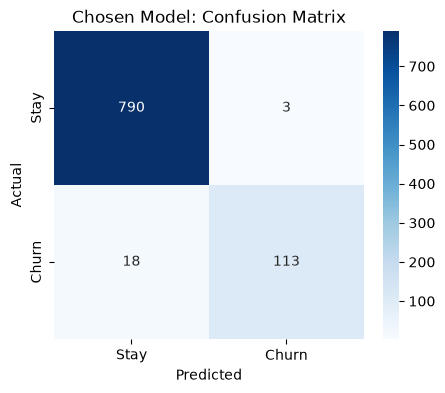

In [49]:
from sklearn.metrics import confusion_matrix, classification_report

best_name = 'HistGradientBoosting (random search)'
best = clone(final_models[best_name]).fit(X_train, y_train)
y_pred = best.predict(X_test)
print(best_name)
print(classification_report(y_test, y_pred))

plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Stay', 'Churn'], yticklabels=['Stay', 'Churn'])
plt.title('Chosen Model: Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

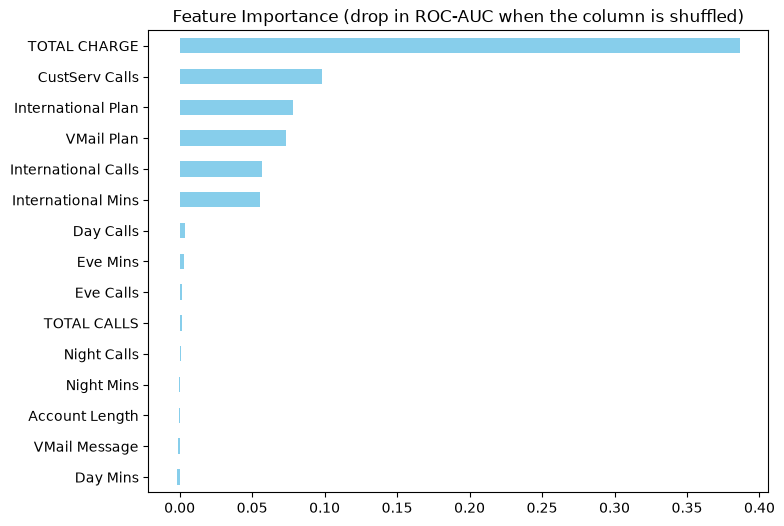

TOTAL CHARGE           0.3868
CustServ Calls         0.0980
International Plan     0.0783
VMail Plan             0.0733
International Calls    0.0571
International Mins     0.0556
Day Calls              0.0034
Eve Mins               0.0031
Eve Calls              0.0018
TOTAL CALLS            0.0014
Night Calls            0.0011
Night Mins            -0.0003
Account Length        -0.0005
VMail Message         -0.0012
Day Mins              -0.0021
dtype: float64

In [50]:
# HistGradientBoosting has no built-in feature_importances_, so we use permutation importance:
# shuffle one column at a time on the test set and measure how much the ROC-AUC drops
from sklearn.inspection import permutation_importance

perm = permutation_importance(best, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=42)
importance = pd.Series(perm.importances_mean, index=features).sort_values()
importance.plot(kind='barh', color='skyblue', figsize=(8,6))
plt.title('Feature Importance (drop in ROC-AUC when the column is shuffled)')
plt.show()
importance.sort_values(ascending=False).round(4)

**Result:** On the test set of 924 customers (131 churners), the model finds **86% of the churners (113 of 131)** and when it says "churn" it is right **97% of the time** (only 3 false alarms out of 793 loyal customers). Overall accuracy is 98%, against 86% for a model that always says "no churn".

**Which variables influence customers to leave (Goal 1)?** The permutation importance shows:
1. **TOTAL CHARGE** is by far the most important (shuffling it drops the AUC by 0.39). Customers with a **high bill (above 75)** leave.
2. **CustServ Calls** (0.10): customers who call customer service **4 or more times** leave.
3. **International Plan** (0.08), together with **International Calls and Mins** (about 0.06 each): international plan customers who make **very few international calls or use a lot of international minutes** leave.
4. **VMail Plan** (0.07): voice mail plan customers are more loyal.

Day/Evening/Night minutes on their own score close to zero only because their effect is already inside TOTAL CHARGE. Account Length, number of calls and voice mail messages have no real effect.

## Churn Risk Score and CHURN-FLAG (Goals 2 and 3)
- **CHURN RISK SCORE (0-100):** the model's probability that the customer will churn, x 100.
- **CHURN-FLAG:** **YES (1)** if the score is above a cut-off, otherwise **NO (0)**. The cut-off is chosen where the F1 score is highest, which balances finding churners (recall) against false alarms (precision).
- To make the scores **honest**, every customer is scored by a model that was trained **without** that customer (5-fold out-of-fold predictions). This is the same as scoring a brand-new customer. Scores made on the training data would look much better than they really are.

In [51]:
from sklearn.model_selection import cross_val_predict

# out-of-fold scores: every customer is scored by a model that did NOT see that customer during training,
# so the scores are honest (the same as scoring brand-new customers)
oof_prob = cross_val_predict(clone(final_models[best_name]), X, y, cv=cv5, method='predict_proba')[:, 1]
print('Out-of-fold ROC-AUC on all 4,617 customers:', round(roc_auc_score(y, oof_prob), 3))

Out-of-fold ROC-AUC on all 4,617 customers: 0.924


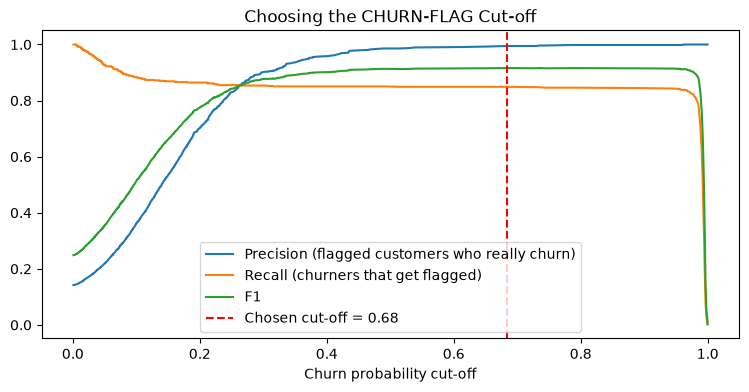

cut-off 0.20 -> flags  806 customers | finds  86.4% of churners |  70.3% of flagged really churn
cut-off 0.30 -> flags  621 customers | finds  85.4% of churners |  90.2% of flagged really churn
cut-off 0.68 -> flags  560 customers | finds  84.9% of churners |  99.5% of flagged really churn
cut-off 0.50 -> flags  565 customers | finds  84.9% of churners |  98.6% of flagged really churn
cut-off 0.70 -> flags  559 customers | finds  84.8% of churners |  99.5% of flagged really churn


In [52]:
from sklearn.metrics import precision_recall_curve

prec, rec, thr = precision_recall_curve(y, oof_prob)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
best_thr = thr[np.argmax(f1[:-1])]

plt.figure(figsize=(9,4))
plt.plot(thr, prec[:-1], label='Precision (flagged customers who really churn)')
plt.plot(thr, rec[:-1], label='Recall (churners that get flagged)')
plt.plot(thr, f1[:-1], label='F1')
plt.axvline(best_thr, color='red', linestyle='--', label=f'Chosen cut-off = {best_thr:.2f}')
plt.title('Choosing the CHURN-FLAG Cut-off')
plt.xlabel('Churn probability cut-off')
plt.legend()
plt.show()

for t in [0.2, 0.3, round(best_thr, 2), 0.5, 0.7]:
    flag = (oof_prob >= t).astype(int)
    print(f'cut-off {t:.2f} -> flags {flag.sum():4} customers | finds {recall_score(y, flag)*100:5.1f}% of churners | '
          f'{precision_score(y, flag)*100:5.1f}% of flagged really churn')

In [53]:
# do the scores rank customers well? split all customers into 10 equal groups (deciles) by risk score
deciles = pd.DataFrame({'score': oof_prob * 100, 'churn': y.values})
deciles['DECILE'] = pd.qcut(deciles['score'].rank(method='first'), 10, labels=[f'D{i}' for i in range(10, 0, -1)])
dec = deciles.groupby('DECILE').agg(customers=('churn', 'count'), min_score=('score', 'min'), max_score=('score', 'max'),
                                    actual_churn_pct=('churn', 'mean'))
dec['actual_churn_pct'] = dec['actual_churn_pct'] * 100
dec.sort_index(ascending=False).round(1)

,customers,min_score,max_score,actual_churn_pct
DECILE,,,,
D1,462,98.9,100.0,100.0
D2,462,17.3,98.9,22.9
D3,461,11.6,17.3,1.1
D4,462,8.7,11.6,2.4
D5,461,6.6,8.7,3.0
D6,462,5.0,6.6,2.2
D7,462,3.7,5.0,3.5
D8,461,2.5,3.7,2.8
D9,462,1.5,2.5,1.9


In [54]:
# below the cut-off, can the score still tell churners from non-churners?
low = oof_prob < best_thr
print('Customers below the cut-off:', low.sum(), '| churners among them:', y[low].sum(),
      f'({y[low].mean()*100:.1f}%)')
print('ROC-AUC inside this group:', round(roc_auc_score(y[low], oof_prob[low]), 3))

Customers below the cut-off: 4057 | churners among them: 99 (2.4%)
ROC-AUC inside this group: 0.499


In [55]:
scored = df[['State', 'Area Code', 'Account Length', 'International Plan', 'VMail Plan', 'Day Mins',
             'CustServ Calls', 'TOTAL CHARGE', 'Churn']].copy()
scored['CHURN RISK SCORE'] = (oof_prob * 100).round(1)
scored['CHURN-FLAG'] = (oof_prob >= best_thr).astype(int)
scored['RISK BAND'] = np.where(scored['CHURN-FLAG'] == 1, 'High Risk', 'Low Risk')
scored['TICKET PRIORITY'] = np.where(scored['CHURN-FLAG'] == 1, 'HIGH', 'NORMAL')

scored.sort_values('CHURN RISK SCORE', ascending=False).head(10)

,State,Area Code,Account Length,International Plan,VMail Plan,Day Mins,CustServ Calls,TOTAL CHARGE,Churn,CHURN RISK SCORE,CHURN-FLAG,RISK BAND,TICKET PRIORITY
1192,MD,415,88,yes,no,235.1,4,76.18,1,100.0,1,High Risk,HIGH
1533,WY,510,127,yes,no,242.2,2,75.48,1,100.0,1,High Risk,HIGH
2401,NY,415,126,yes,no,239.7,1,76.03,1,100.0,1,High Risk,HIGH
2732,NC,408,130,yes,no,216.2,5,77.92,1,100.0,1,High Risk,HIGH
1339,WA,415,90,yes,no,148.2,4,52.44,1,99.9,1,High Risk,HIGH
985,NY,415,64,yes,no,346.8,1,96.15,1,99.9,1,High Risk,HIGH
2614,NH,415,125,yes,no,298.4,0,81.84,1,99.9,1,High Risk,HIGH
815,KY,415,75,no,no,314.6,2,82.28,1,99.9,1,High Risk,HIGH
1534,OR,510,136,no,no,259.4,1,74.89,1,99.9,1,High Risk,HIGH
230,MD,408,93,yes,no,312.0,0,76.67,1,99.9,1,High Risk,HIGH


In [56]:
band = scored.groupby('RISK BAND').agg(customers=('Churn', 'count'), actual_churn_pct=('Churn', 'mean'),
                                       avg_risk_score=('CHURN RISK SCORE', 'mean'))
band['share_of_all_churners_pct'] = scored.groupby('RISK BAND')['Churn'].sum() / scored['Churn'].sum() * 100
band['actual_churn_pct'] = band['actual_churn_pct'] * 100
band.round(1)

,customers,actual_churn_pct,avg_risk_score,share_of_all_churners_pct
RISK BAND,,,,
High Risk,560,99.5,98.9,84.9
Low Risk,4057,2.4,7.6,15.1


In [57]:
flag_table = pd.crosstab(scored['CHURN-FLAG'], scored['Churn'], margins=True)
flag_table.index = ['CHURN-FLAG = NO (0)', 'CHURN-FLAG = YES (1)', 'Total']
flag_table.columns = ['Actually stayed', 'Actually churned', 'Total']
flag_table

,Actually stayed,Actually churned,Total
CHURN-FLAG = NO (0),3958,99,4057
CHURN-FLAG = YES (1),3,557,560
Total,3961,656,4617


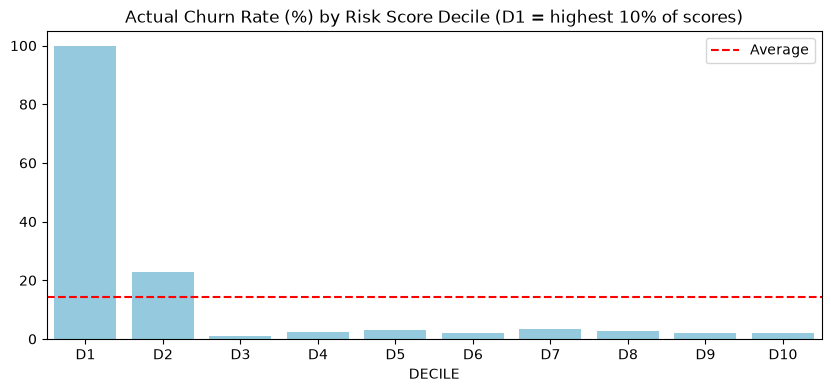

In [58]:
plt.figure(figsize=(10,4))
rate = dec['actual_churn_pct'].sort_index(ascending=False)
sns.barplot(x=rate.index.astype(str), y=rate.values, color='skyblue')
plt.axhline(scored['Churn'].mean() * 100, color='red', linestyle='--', label='Average')
plt.title('Actual Churn Rate (%) by Risk Score Decile (D1 = highest 10% of scores)')
plt.legend()
plt.show()

In [59]:
# file for the CRM / email campaign team: one row per customer with the risk score, flag and ticket priority
scored.to_csv('No_Churn_Customer_Risk_Scores.csv', index_label='Customer Row')
scored['TICKET PRIORITY'].value_counts()

TICKET PRIORITY
NORMAL    4057
HIGH       560
Name: count, dtype: int64

**Results**
- **CHURN-FLAG = YES for 560 customers.** **557 of them really churned (99.5%)**, so the email campaign with lucrative offers would almost never be wasted on a loyal customer. These customers include **84.9% of all 656 churners**.
- The cut-off chosen by F1 is **0.68**. The table shows that any cut-off from 0.3 to 0.7 flags almost the same customers, because the model is very sure about them (most flagged customers have a score above 90).
- **The risk score is very sharp at the top:** the highest decile (D1) has an actual churn rate of **100%**, the second decile (D2) has **22.9%** because it holds the rest of the flagged customers, and deciles D3 to D10 are all between **1.1% and 3.5%**.
- **Below the cut-off, the score does not rank customers any further.** The 4,057 customers below it still include 99 churners (2.4%), but inside this group the ROC-AUC is only **0.499**, which is no better than guessing. These customers do not show any sign in the data (bill, service calls, plans) that separates them from loyal customers. This is why the risk bands are kept to **two honest levels (High Risk / Low Risk)** instead of inventing "Medium" levels that would not mean anything.
- **TICKET PRIORITY:** all 560 CHURN-FLAG = YES customers get **HIGH** priority, so their questions and complaints are answered first. That is **12.1% of the customer base**, which is a manageable load for customer care.
- The scores, flags and priorities for all 4,617 customers are saved in **`No_Churn_Customer_Risk_Scores.csv`** for the CRM and email campaign teams.

# Part 3: Suggestions for the Retention and Customer Care Teams

## Which customers should No-Churn focus on?

In [60]:
groups = {
    'All customers': df,
    'International Plan = yes': df[df['International Plan'] == 'yes'],
    'International Plan = no': df[df['International Plan'] == 'no'],
    'VMail Plan = yes': df[df['VMail Plan'] == 'yes'],
    'VMail Plan = no': df[df['VMail Plan'] == 'no'],
    '4+ customer service calls': df[df['CustServ Calls'] >= 4],
    '0-3 customer service calls': df[df['CustServ Calls'] <= 3],
    'Day Mins above 250': df[df['Day Mins'] > 250],
    'Total charge above 75': df[df['TOTAL CHARGE'] > 75],
}
segment = pd.DataFrame({name: [len(g), g['Churn'].mean() * 100] for name, g in groups.items()},
                       index=['Customers', 'Churn %']).T
segment['Customers'] = segment['Customers'].astype(int)
segment.sort_values('Churn %', ascending=False).round(1)

,Customers,Churn %
Total charge above 75,313,74.4
4+ customer service calls,368,50.8
Day Mins above 250,455,46.2
International Plan = yes,446,41.7
VMail Plan = no,3381,16.5
All customers,4617,14.2
International Plan = no,4171,11.3
0-3 customer service calls,4249,11.0
VMail Plan = yes,1236,7.8


In [61]:
# fair comparison 1: are customer service calls a problem on their own, or only because of the international plan?
# compare 0-3 vs 4+ calls INSIDE each plan group
df['CUSTSERV 4+'] = np.where(df['CustServ Calls'] >= 4, '4+ calls', '0-3 calls')
pd.crosstab(df['International Plan'], df['CUSTSERV 4+'], values=df['Churn'], aggfunc='mean').mul(100).round(1)

CUSTSERV 4+,0-3 calls,4+ calls
International Plan,,
no,8.1,48.6
yes,39.1,69.2


In [62]:
pd.crosstab(df['International Plan'], df['CUSTSERV 4+'])

CUSTSERV 4+,0-3 calls,4+ calls
International Plan,,
no,3842,329
yes,407,39


In [63]:
# fair comparison 2: do heavy day users leave because they use a lot, or because of the bill?
# compare inside the voice mail plan groups (voice mail plan customers have a different usage pattern)
df['HEAVY DAY USER'] = np.where(df['Day Mins'] > 250, 'Day Mins > 250', 'Day Mins <= 250')
pd.crosstab(df['VMail Plan'], df['HEAVY DAY USER'], values=df['Churn'], aggfunc='mean').mul(100).round(1)

HEAVY DAY USER,Day Mins <= 250,Day Mins > 250
VMail Plan,,
no,11.8,58.7
yes,7.9,7.2


In [64]:
pd.crosstab(df['VMail Plan'], df['HEAVY DAY USER'])

HEAVY DAY USER,Day Mins <= 250,Day Mins > 250
VMail Plan,,
no,3037,344
yes,1125,111


In [65]:
# fair comparison 3: international plan customers - who leaves? (split by international minutes and calls)
intl = df[df['International Plan'] == 'yes'].copy()
intl['INTL USAGE'] = np.where(intl['International Mins'] > 13, 'More than 13 intl mins',
                              np.where(intl['International Calls'] <= 2, '2 or fewer intl calls', 'Normal use'))
intl.groupby('INTL USAGE').agg(customers=('Churn', 'count'), churn_pct=('Churn', 'mean')).assign(churn_pct=lambda t: (t.churn_pct * 100).round(1))

,customers,churn_pct
INTL USAGE,,
2 or fewer intl calls,74,100.0
More than 13 intl mins,76,100.0
Normal use,296,12.2


In [66]:
# customers without the international plan who still make a lot of international calls / minutes
no_plan = df[df['International Plan'] == 'no']
print('No intl plan, more than 13 intl mins:', (no_plan['International Mins'] > 13).sum(), 'customers, churn',
      round(no_plan.loc[no_plan['International Mins'] > 13, 'Churn'].mean() * 100, 1), '%')
print('No intl plan, 13 or fewer intl mins :', (no_plan['International Mins'] <= 13).sum(), 'customers, churn',
      round(no_plan.loc[no_plan['International Mins'] <= 13, 'Churn'].mean() * 100, 1), '%')

No intl plan, more than 13 intl mins: 615 customers, churn 12.2 %
No intl plan, 13 or fewer intl mins : 3556 customers, churn 11.1 %


In [67]:
# how much revenue is at risk? (monthly charges of the customers in each risk band)
rev = scored.groupby('RISK BAND').agg(customers=('Churn', 'count'), monthly_charge=('TOTAL CHARGE', 'sum'),
                                      avg_charge=('TOTAL CHARGE', 'mean'))
rev['share_of_revenue_pct'] = rev['monthly_charge'] / rev['monthly_charge'].sum() * 100
rev.round(1)

,customers,monthly_charge,avg_charge,share_of_revenue_pct
RISK BAND,,,,
High Risk,560,37171.5,66.4,13.5
Low Risk,4057,237620.3,58.6,86.5


## Suggestions for the Retention, Campaign and Customer Care Teams

**A note on fair comparison:** some risk factors overlap. For example, international plan customers may also call customer service more. To be sure each factor matters **on its own**, it is checked **inside the same group** (e.g. 4+ service calls is compared within plan holders and within non-plan holders separately).

### 1. Target the high-bill customers with a better tariff (biggest group of churners)
| Total monthly charge | Churn rate |
|---|---|
| 60-70 | about 6% |
| 70-75 | 16.7% |
| **above 75** | **74.4%** (313 customers) |

The fair comparison confirms it is about the bill, not the usage: among **customers without voice mail**, heavy day users (above 250 day minutes) churn **58.7%**, but among **customers with voice mail** heavy day users churn only **7.2%**, the same as light users (7.9%). Voice mail plan customers probably see their bundle as better value for money.
- **Offer a flat-rate or capped "unlimited day calls" plan** to customers whose bill goes above 70. They are paying the most and leaving the most, so a discount here protects the most valuable revenue.
- **Bundle voice mail** (or another add-on) into the offer for heavy users, since heavy users with voice mail are as loyal as everyone else.

### 2. Treat the 4th customer service call as an alarm
| | 0-3 service calls | 4+ service calls |
|---|---|---|
| No international plan | 8.1% | **48.6%** |
| International plan | 39.1% | **69.2%** |

Within **both** groups, 4+ calls makes churn about **6 times higher** (no plan) or almost **2 times higher** (plan). So repeated calls are a reason for leaving on their own: the customer has a problem that was not solved.
- **Auto-escalate** any customer making their **4th call** to a senior agent or a retention specialist, and mark the ticket **HIGH priority**.
- Track **first-call resolution**: the goal is that customers never need a 4th call.
- After the 3rd call, have someone call the customer back to check the problem is really fixed.

### 3. Fix the International Plan
- International plan customers churn **41.7%**, almost 4 times more than others (11.3%).
- Inside the plan group: **every single customer (100%) who made 2 or fewer international calls (74 customers) or used more than 13 international minutes (76 customers) left.** Customers with normal international use churn only 12.2%, the same as non-plan customers.
- So the plan does not fit two kinds of customers: those who **pay for it but hardly use it** (it feels like a waste of money) and those who **use it heavily** (the price per minute is too high, 0.27, and competitors probably offer cheaper international rates).
- **Suggestions:** contact plan holders with very low international use and offer to **remove the plan or switch to pay-as-you-go**; give heavy international users a **cheaper per-minute rate or an international minutes bundle**. Customers without the plan who use a lot of international minutes do **not** churn more (12.2%), so the problem is the plan's value, not international calling itself.

### 4. How to use the Churn Risk Score and CHURN-FLAG
- **Email campaign:** send the lucrative offers only to **CHURN-FLAG = YES** customers (560 customers). 99.5% of them really are about to leave, so very little of the campaign budget is wasted.
- **Match the offer to the reason** using the three rules above: high bill → tariff discount; 4+ service calls → service recovery call + goodwill credit; international plan problem → plan change.
- **Customer care:** mark all CHURN-FLAG = YES tickets as **HIGH priority** and show the risk score to the agent at every touch point (calls, request fulfilment, store visits).
- **Re-score every month:** the score is based on usage, bills and service calls, which change every month. A customer can move into the high-risk group after one expensive month or one bad service experience.
- **Revenue at risk:** the High Risk group is 12.1% of customers but **13.5% of the monthly revenue**, because they are the high-bill customers. Keeping even half of them is worth far more than a small discount.

### 5. What the data cannot explain
About **99 churners (15.1% of all churners)** look exactly like loyal customers in this data. They probably leave for reasons that are not recorded here (network quality, a competitor's phone offer, moving house). Collecting **network quality, complaint type, contract end date and competitor offers** would be needed to find them.

# Model Comparison Report

**Goal:** Predict whether a customer will **churn (yes / no)** from their usage, bill, plans and customer service calls, and turn the prediction into a **Churn Risk Score** and a **CHURN-FLAG**. The data has 4,617 customers (14.2% churners), split 80% for training and 20% for testing, keeping the same churn rate in both.

### First comparison: 5 algorithms (hand-picked settings)
| Model | Train AUC | Test AUC | Accuracy | Precision | Recall | F1 | 5-fold CV AUC |
|---|---|---|---|---|---|---|---|
| **Gradient Boosting** | 0.988 | **0.920** | 0.976 | 0.958 | **0.870** | 0.912 | **0.923** ± 0.015 |
| Random Forest | 0.999 | 0.914 | **0.977** | **0.966** | **0.870** | **0.916** | 0.918 ± 0.015 |
| Decision Tree | 0.961 | 0.911 | 0.970 | 0.933 | 0.847 | 0.888 | 0.916 ± 0.024 |
| KNN | 0.946 | 0.882 | 0.893 | 0.848 | 0.298 | 0.441 | 0.886 ± 0.008 |
| Logistic Regression | 0.833 | 0.812 | 0.774 | 0.360 | 0.763 | 0.489 | 0.824 ± 0.015 |

### Tuned models and ensembles
| Model | Test AUC | Test PR-AUC | Precision | Recall | F1 | Churners in top 20% | 5-fold CV AUC |
|---|---|---|---|---|---|---|---|
| **HistGradientBoosting (random search)** | **0.946** | **0.917** | 0.974 | 0.863 | 0.915 | 88.5% | **0.925** ± 0.019 |
| Random Forest (grid search) | 0.912 | 0.894 | 0.782 | **0.878** | 0.827 | 87.8% | 0.924 ± 0.011 |
| Gradient Boosting (default) | 0.920 | 0.893 | 0.958 | 0.870 | 0.912 | 87.8% | 0.923 ± 0.015 |
| Random Forest (random search) | 0.918 | 0.900 | 0.982 | 0.840 | 0.905 | 87.8% | 0.921 ± 0.016 |
| Soft Voting | 0.930 | 0.911 | **0.991** | 0.870 | **0.927** | **89.3%** | 0.920 ± 0.020 |
| Stacking | 0.930 | 0.911 | 0.974 | 0.870 | 0.919 | **89.3%** | 0.920 ± 0.019 |
| Random Forest (hand-picked) | 0.915 | 0.899 | 0.966 | 0.870 | 0.916 | 87.8% | 0.918 ± 0.015 |

*ROC-AUC = how well the model ranks a churner above a loyal customer (1.0 is perfect, 0.5 is guessing). PR-AUC focuses on how well the churners are found. Recall = share of real churners found. Precision = share of flagged customers who really churn.*

**Conclusion:** the tree-based models (Gradient Boosting, Random Forest, HistGradientBoosting, Decision Tree) are clearly better than Logistic Regression and KNN, because churn follows **sharp thresholds** (bill above 75, 4+ service calls, international plan usage) that trees capture naturally. Tuning and ensembles improved the cross-validated AUC by less than 0.01, so all good models reach the same limit of about 0.92: they all find the same ~85% of churners and miss the same ~15%, who show no warning signs in this data. The **tuned HistGradientBoosting** is chosen because it has the highest CV AUC (0.925) and test AUC (0.946) with 97% precision, which suits a targeted email campaign. Its out-of-fold predictions give the **Churn Risk Score** and **CHURN-FLAG** for every customer.

# Report on Challenges Faced

| # | Challenge in the data | Technique used | Reason |
|---|---|---|---|
| 1 | **Database table had changed:** the table named in the project document returned a different 243,553-row dataset with random churn (every model scored AUC 0.50), not the 4,617 rows described. | Loaded the same 4,617 rows from the public source of this dataset and **verified** them against an earlier run of this project (all column statistics to 6 decimals, the churn rate and 10 sample rows match). | Building a model on the wrong table would give meaningless results. Verifying against known outputs proves the data is the same, not just similar. |
| 2 | **Target stored as text** (`'True.'` / `'False.'` with a full stop). | Stripped the full stop and mapped to 1 / 0. | Models need a numeric target, and a simple `== 'True'` check would fail because of the full stop. |
| 3 | **Redundant columns:** every Charge column is Minutes x a fixed price (correlation 1.00). | Dropped the 4 Charge columns and combined them into one new `TOTAL CHARGE` column. | Duplicate columns split the importance between copies and add nothing. The **total bill** turned out to be the strongest predictor of all, much stronger than any single part of it. |
| 4 | **Imbalanced target:** only 14.2% churners. | Stratified train/test split, `class_weight='balanced'`, and scoring on ROC-AUC, recall, precision and F1 instead of accuracy. | A model that always says "no churn" is 86% accurate and useless. Balanced weights make the model pay attention to the small churn class. |
| 5 | **Outliers** in service calls, day minutes and total charge. | Kept all of them (checked with IQR). | They are real customers and they churn at 50-58%, so they are the most important customers to find. Tree models are not affected by extreme values. |
| 6 | **Categorical columns with many levels:** 51 states, 3 area codes. | Tested with a chi-square test, then dropped `State` and `Area Code` from the model. | Area code has no link with churn (p = 0.67). State differences exist (p = 0.0004), but with 44-149 customers per state they are too noisy, and label-encoded state numbers are just alphabetical order. |
| 7 | **Non-linear, threshold-type patterns** (flat churn up to 3 service calls or a bill of 75, then a big jump). | Tree-based models (Random Forest, Gradient Boosting, HistGradientBoosting). | Straight-line models like Logistic Regression can't model sudden jumps (AUC 0.82 vs 0.92 for trees). |
| 8 | **Overlapping risk factors** (e.g. international plan holders also call customer service more). | **Fair comparison**: checked each factor inside the same group (service calls within plan / no plan, heavy use within voice mail / no voice mail). | To make sure each suggestion targets a real cause and is not just a side effect of another factor. |
| 9 | **Honest risk scores:** scoring customers with a model that was trained on them gives over-confident scores. | 5-fold out-of-fold predictions (`cross_val_predict`) for every customer. | Every score comes from a model that never saw that customer, so the score behaves like it will on new customers. |
| 10 | **Scores do not rank customers below the cut-off** (AUC about 0.5 inside that group). | Checked the churn rate by score decile and used **two honest risk bands** (High / Low) instead of four. | Bands like "Medium" would suggest a difference in risk that does not exist in the data, and would waste retention budget. |